# INTELIGENCIA ARTIFICIAL (1INF24) — Tarea Académica, Grupo 7
## Predicción de condiciones ambientales desfavorables a partir de variables atmosféricas en Lima

**Integrantes:** Aarón Dianderas Guerrero (20211709), Ariel Jair LLaiqui Rojas (20222757), Pablo Orlando Huayta Almonacid (20267546)

**Qué hace este notebook**
1. Carga y explora el dataset diario de calidad del aire de Lima (ago 2022 – feb 2026).
2. Construye las variables de entrada: 9 variables atmosféricas de hoy y de hace 1, 7, 14 y 30 días, más el mes.
3. **Regresión:** pronostica el ozono (µg/m³) a 1, 7 y 30 días.
4. **Clasificación:** pronostica si el día será *Favorable*, *Moderado* o *Desfavorable* según su nivel de ozono.
5. Compara 4 modelos (regresión lineal/logística, árbol de decisión, KNN y red neuronal MLP) contra dos referencias simples (persistencia y media mensual).

**Para ejecutarlo en Google Colab:** subir `air_quality_historical.csv` a la sesión (ícono de carpeta) y ejecutar todo.

## 1. Librerías y constantes

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit, cross_val_score, GridSearchCV
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             balanced_accuracy_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

SEED = 7                      # semilla para reproducibilidad
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
plt.rcParams['figure.figsize'] = [9, 4.5]

# Las 9 variables atmosféricas del dataset (los índices AQI se excluyen, ver sección 3)
VARS = ['ozone', 'pm2_5', 'pm10', 'carbon_monoxide', 'nitrogen_dioxide',
        'sulphur_dioxide', 'aerosol_optical_depth', 'dust', 'uv_index']
RETRASOS   = [0, 1, 7, 14, 30]     # hoy y hace 1, 7, 14 y 30 días
HORIZONTES = [1, 7, 30]            # días hacia adelante que se pronostican
FIN_TRAIN  = '2024-12-31'          # entrenamiento: 2022-2024 | prueba: 2025-feb 2026
QUIEBRE    = '2024-11-12'          # fecha en que cambia el modelo CAMS (ver sección 3.1)
CLASES     = ['Favorable', 'Moderado', 'Desfavorable']

## 2. Carga y limpieza del dataset
Dataset: *Air Quality Dataset for Lima* (Kaggle, Kulkarni 2026), obtenido del servicio de calidad del aire de Open-Meteo (modelo global CAMS). Un registro por día para un punto de Lima.

In [2]:
df = pd.read_csv('air_quality_historical.csv', parse_dates=['date']).set_index('date')
print('Filas y columnas:', df.shape)
print('Desde', df.index.min().date(), 'hasta', df.index.max().date())
df.head()

Filas y columnas: (1298, 11)
Desde 2022-08-01 hasta 2026-02-18


,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,aerosol_optical_depth,dust,uv_index,us_aqi,european_aqi
date,,,,,,,,,,,
2022-08-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022-08-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022-08-03,23.320000,13.400000,176.400000,19.860000,5.840000,43.800000,0.224000,0.600,0.000000,NaN,NaN
2022-08-04,21.795833,12.670833,139.958333,12.500000,6.537500,56.083333,0.232917,0.125,1.170833,52.40,26.200000
2022-08-05,19.387500,11.383333,142.666667,12.029167,6.129167,58.125000,0.240417,0.000,1.293750,48.75,24.916667


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
pm10,1296.0,25.651102,9.950202,0.983333,17.282292,22.664583,34.929167,62.383333
pm2_5,1296.0,12.922791,3.265127,0.691667,10.500000,12.879167,14.937500,33.591667
carbon_monoxide,1296.0,290.850521,206.367307,59.500000,148.739583,187.687500,376.562500,1185.125000
nitrogen_dioxide,1296.0,13.808399,3.331642,0.000000,11.378125,13.456250,15.794792,30.612500
sulphur_dioxide,1296.0,5.736409,3.491437,0.695833,3.619792,4.791667,6.458333,25.666667
ozone,1296.0,45.406674,9.369963,17.208333,38.708333,45.791667,52.052083,73.250000
aerosol_optical_depth,1296.0,0.274140,0.080611,0.043333,0.217396,0.261458,0.319583,0.632917
dust,1296.0,12.511073,17.444111,0.000000,0.000000,0.041667,30.375000,77.583333
uv_index,1296.0,2.191337,0.545378,0.000000,1.745312,2.222917,2.641667,3.395833
us_aqi,1295.0,50.235959,9.091313,12.958333,44.083333,52.083333,56.145833,91.291667


In [4]:
# Revisión de calidad: valores nulos, fechas repetidas y días faltantes
print('Nulos por columna:\n', df.isnull().sum())
print('\nFechas duplicadas:', df.index.duplicated().sum())
print('Días faltantes en el calendario:', len(pd.date_range(df.index.min(), df.index.max())) - len(df))

Nulos por columna:
 pm10                     2
pm2_5                    2
carbon_monoxide          2
nitrogen_dioxide         2
sulphur_dioxide          2
ozone                    2
aerosol_optical_depth    2
dust                     2
uv_index                 2
us_aqi                   3
european_aqi             3
dtype: int64

Fechas duplicadas: 0
Días faltantes en el calendario: 0


In [5]:
df[df.isnull().any(axis=1)]

,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,aerosol_optical_depth,dust,uv_index,us_aqi,european_aqi
date,,,,,,,,,,,
2022-08-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022-08-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022-08-03,23.32,13.4,176.4,19.86,5.84,43.8,0.224,0.6,0.0,NaN,NaN


La serie no tiene saltos de fecha ni días repetidos. Los únicos nulos están en los **primeros días** (el servicio aún no tenía datos), así que esas filas se eliminan: no se puede imputar algo que no tiene valores anteriores. Los índices AQI no se usan como entrada, por lo que su nulo adicional no afecta.

In [6]:
df = df.dropna(subset=VARS)
print('Filas restantes:', len(df), '| Nulos en las 9 variables:', int(df[VARS].isnull().sum().sum()))

Filas restantes: 1296 | Nulos en las 9 variables: 0


## 3. Exploración inicial

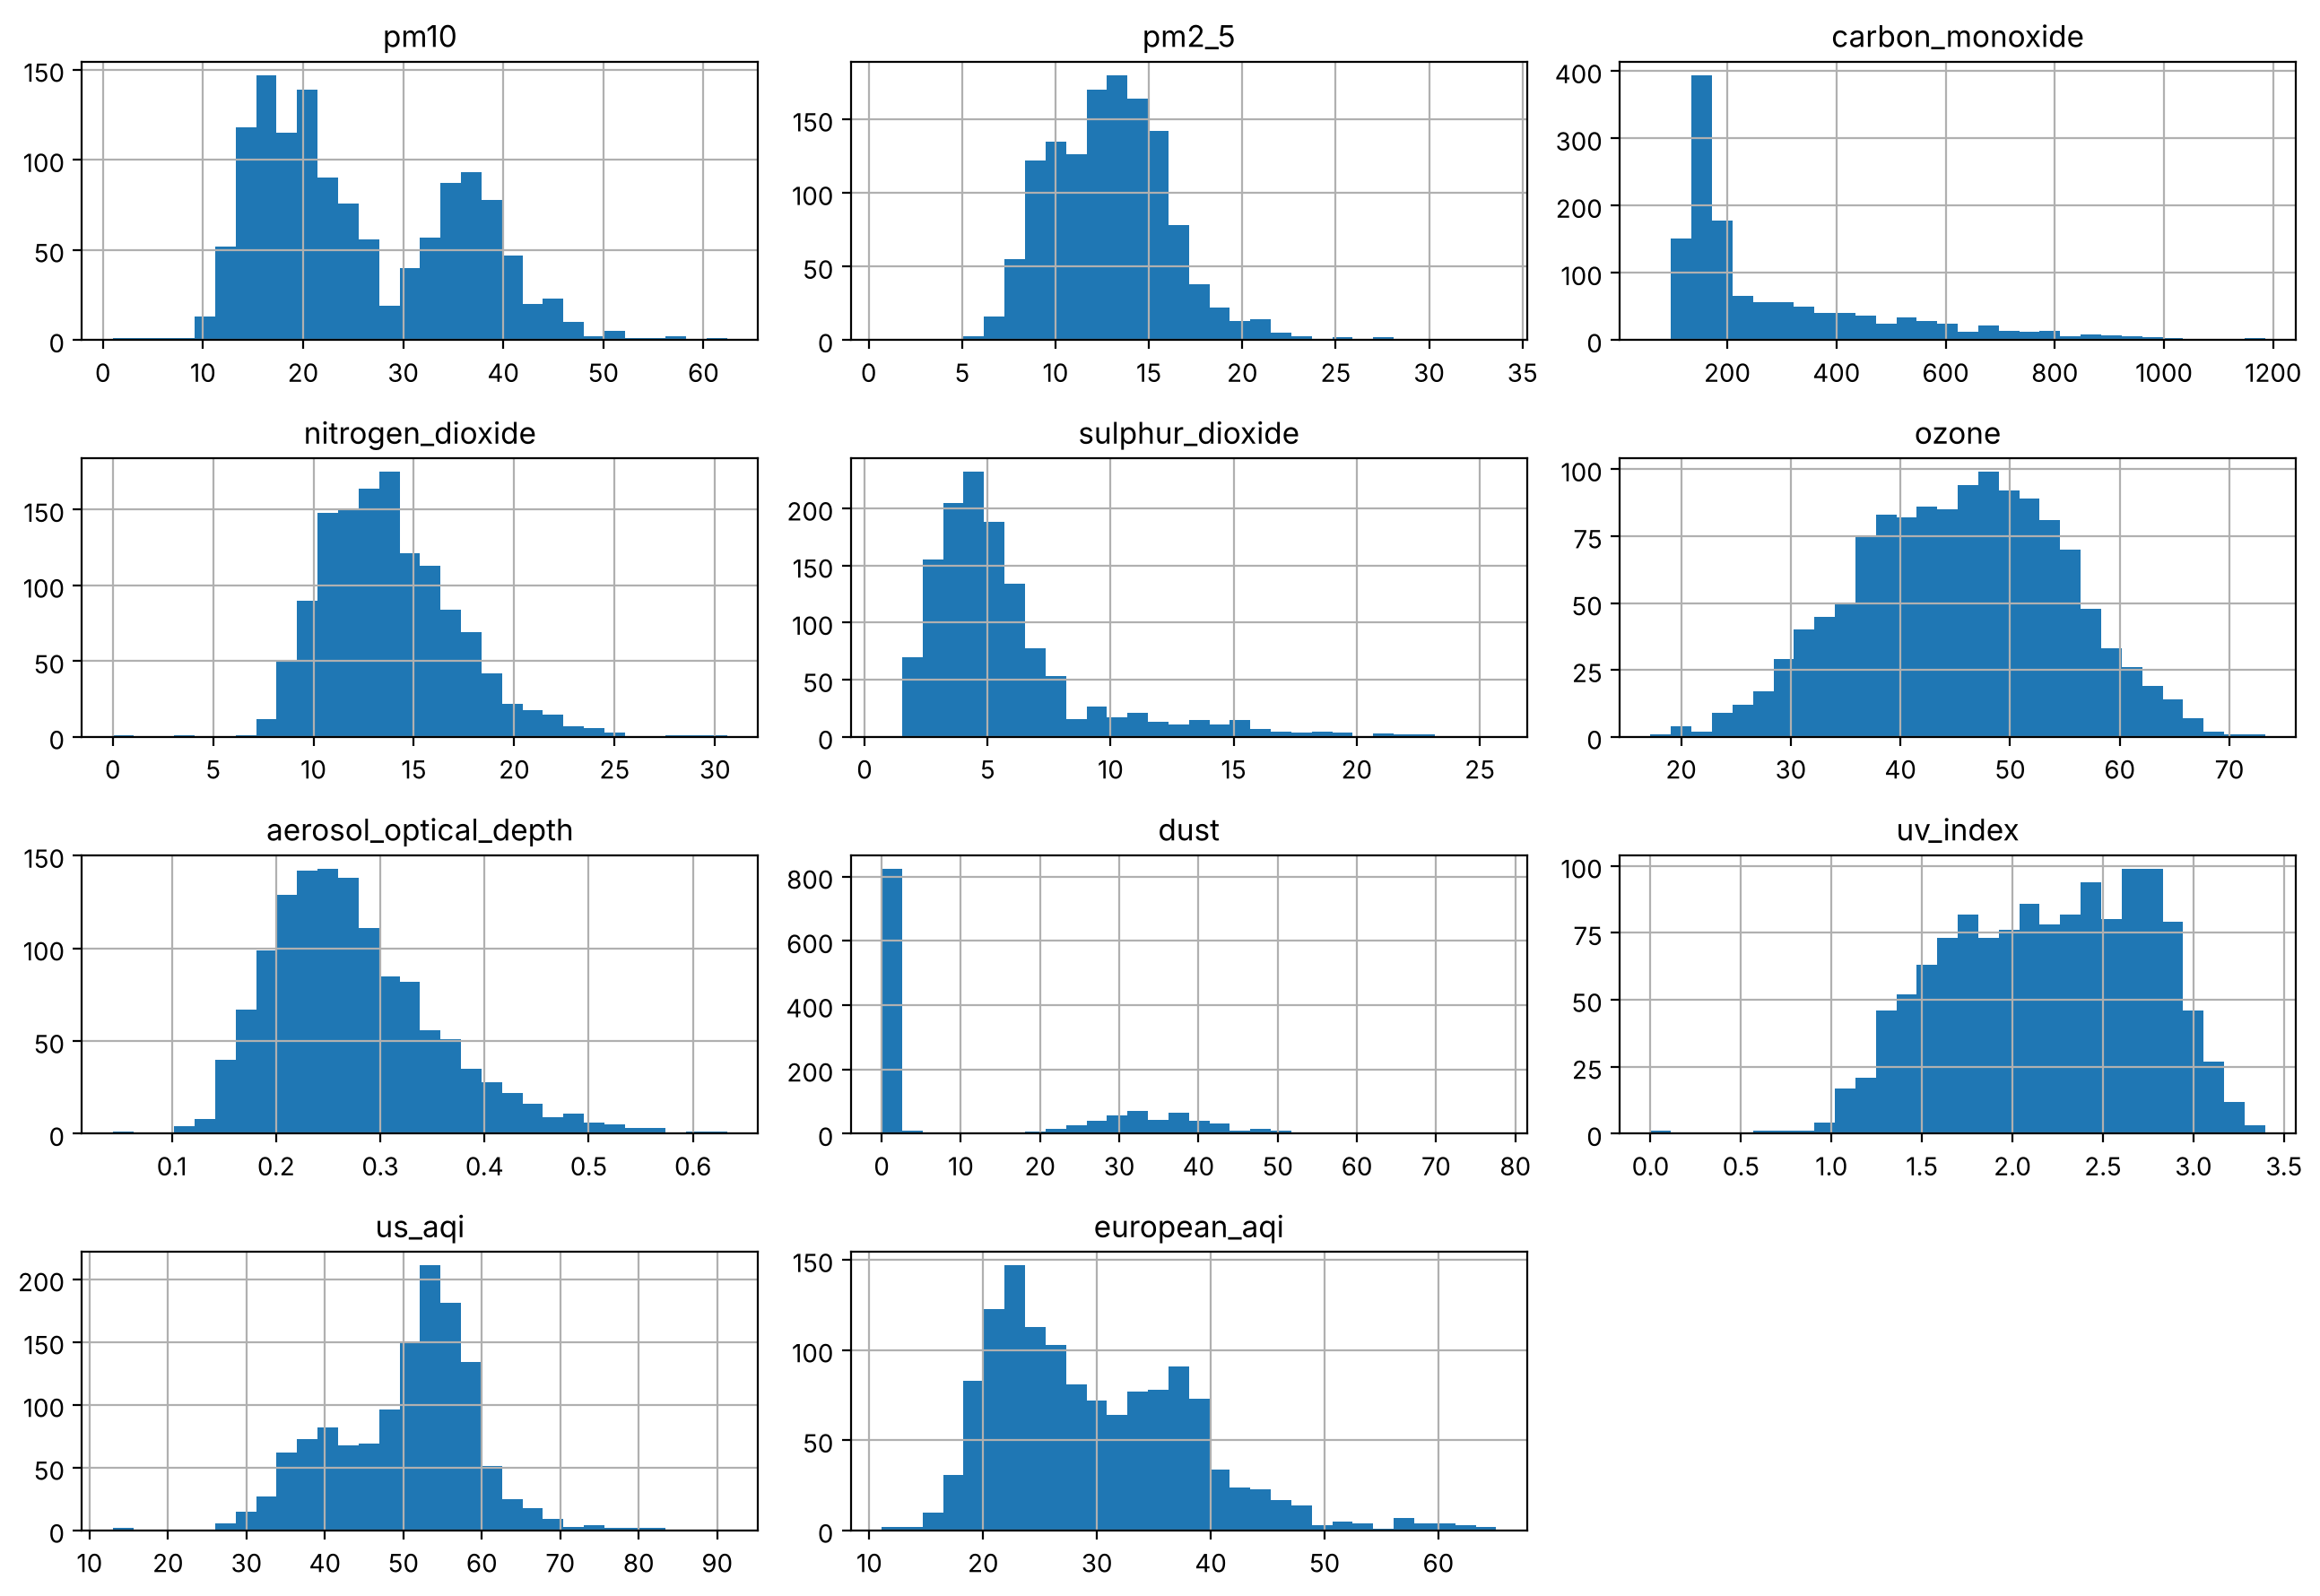

In [7]:
# Distribución de las variables
df.hist(figsize=[13, 9], bins=30)
plt.tight_layout()
plt.show()

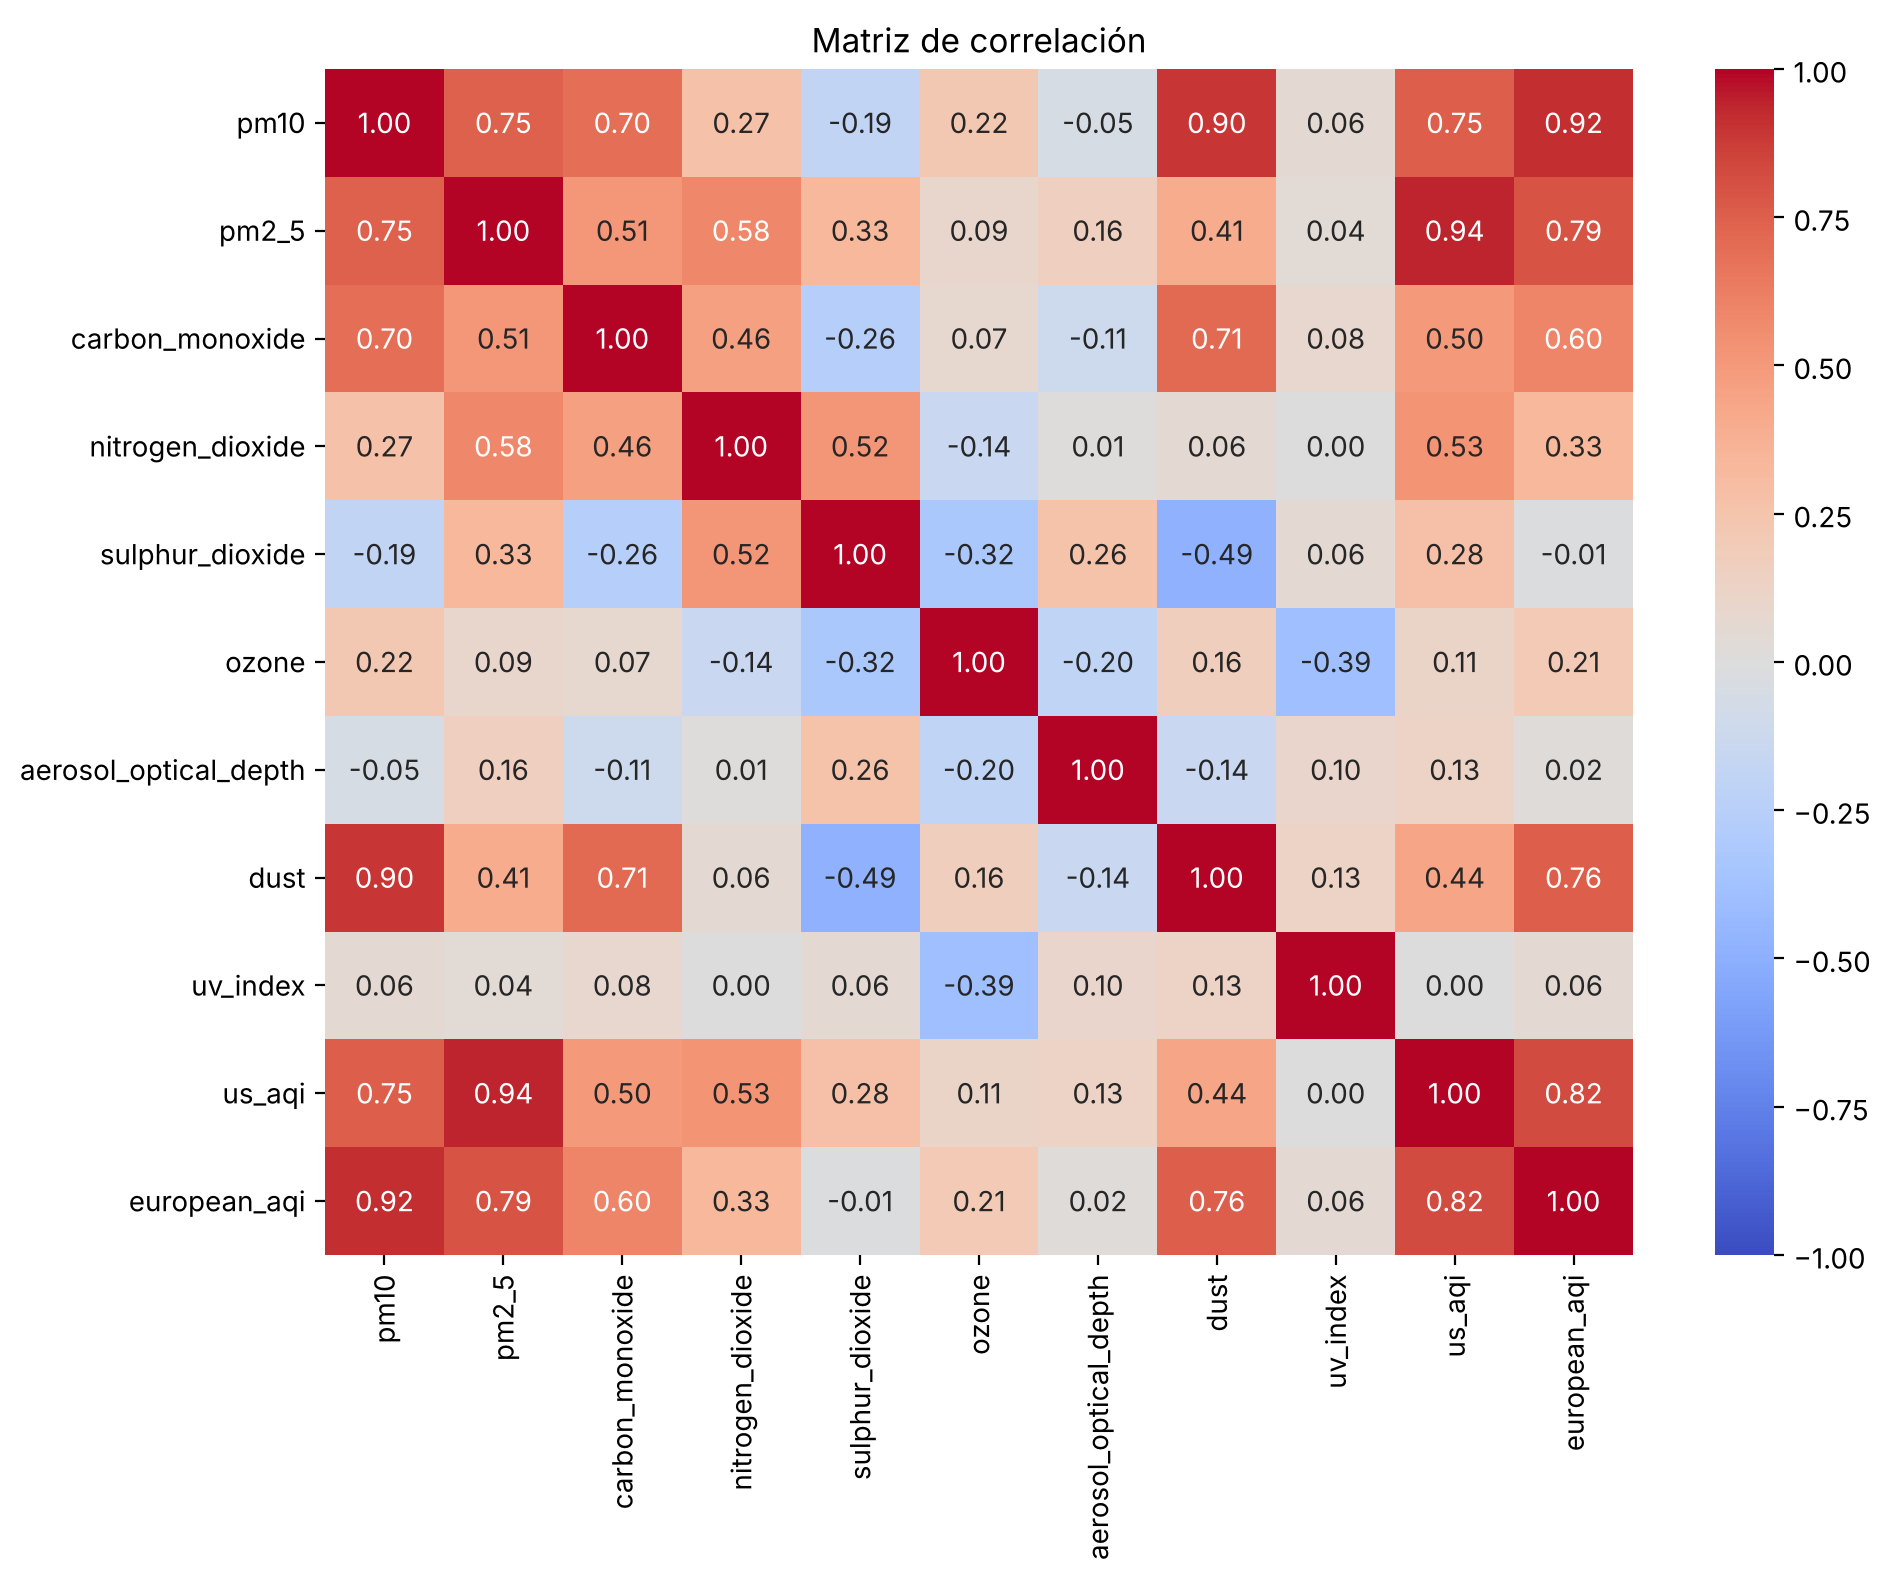

In [8]:
# Matriz de correlación
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Matriz de correlación')
plt.tight_layout()
plt.savefig('fig_correlacion.png', dpi=150)
plt.show()

**¿Por qué no usamos el índice AQI del dataset como etiqueta?** La correlación muestra que `us_aqi` y `european_aqi` dependen casi por completo del material particulado (PM2.5 y PM10) y casi nada del ozono. Además, sus categorías cambian mucho de un año a otro:

In [9]:
print('Correlación del us_aqi con PM2.5: %.2f | con ozono: %.2f' % (df.us_aqi.corr(df.pm2_5), df.us_aqi.corr(df.ozone)))
aqi_moderado = (df.us_aqi > 50)
print('\nProporción de días con us_aqi > 50 ("Moderado") por año:')
print(aqi_moderado.groupby(df.index.year).mean().round(2))

Correlación del us_aqi con PM2.5: 0.94 | con ozono: 0.11

Proporción de días con us_aqi > 50 ("Moderado") por año:
date
2022    0.81
2023    0.48
2024    0.22
2025    0.95
2026    0.98
Name: us_aqi, dtype: float64


En 2025–2026 casi todos los días serían "Moderado", así que un modelo que siempre responda lo mismo acertaría sin aprender nada. Por eso **definimos la condición ambiental a partir del ozono** (sección 5) y dejamos los índices AQI fuera de las entradas.

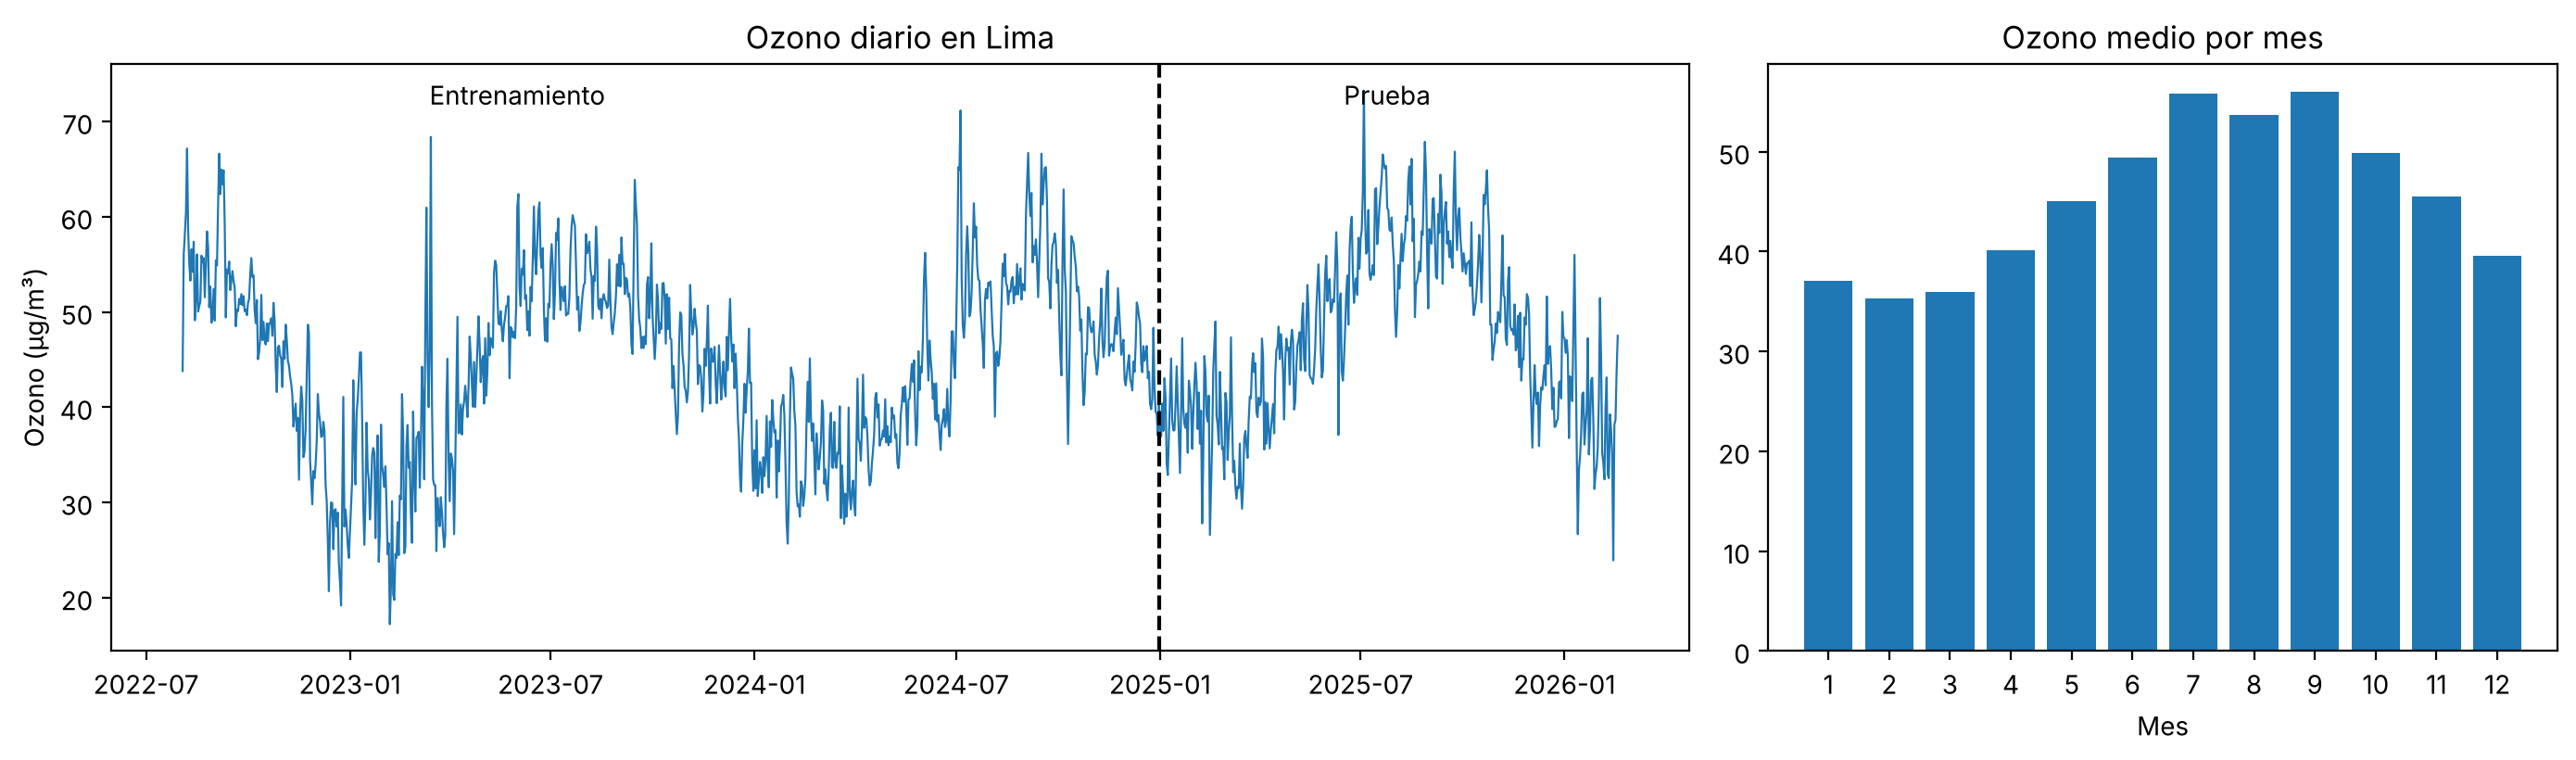

In [10]:
# Serie de ozono y estacionalidad mensual
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={'width_ratios': [2, 1]})
ax[0].plot(df.index, df.ozone, lw=0.8, color='tab:blue')
ax[0].axvline(pd.Timestamp(FIN_TRAIN), color='k', ls='--')
ax[0].text(pd.Timestamp('2023-06-01'), df.ozone.max()*0.98, 'Entrenamiento', ha='center')
ax[0].text(pd.Timestamp('2025-07-25'), df.ozone.max()*0.98, 'Prueba', ha='center')
ax[0].set_title('Ozono diario en Lima'); ax[0].set_ylabel('Ozono (µg/m³)')
media_mes = df.ozone.groupby(df.index.month).mean()
ax[1].bar(media_mes.index, media_mes.values, color='tab:blue')
ax[1].set_xticks(range(1, 13)); ax[1].set_xlabel('Mes'); ax[1].set_title('Ozono medio por mes')
plt.tight_layout()
plt.savefig('fig_ozono.png', dpi=150)
plt.show()

In [11]:
print('Autocorrelación del ozono a 1, 7 y 30 días:',
      [round(df.ozone.autocorr(k), 2) for k in HORIZONTES])

Autocorrelación del ozono a 1, 7 y 30 días: [np.float64(0.89), np.float64(0.72), np.float64(0.6)]


**Hallazgos principales**
- El ozono es **estacional**: sube entre junio y octubre (invierno–primavera) y baja en verano.
- El ozono de hoy se parece mucho al de ayer (autocorrelación alta), y esa relación se debilita con los días. Por eso tiene sentido usar valores pasados como entrada, y por eso la referencia "mañana será igual que hoy" es difícil de superar a 1 día.

### 3.1 Estabilidad de las variables en el tiempo
Antes de usar las 9 variables como entrada, se revisa que se comporten igual en todo el período. Aquí aparece un hallazgo importante:

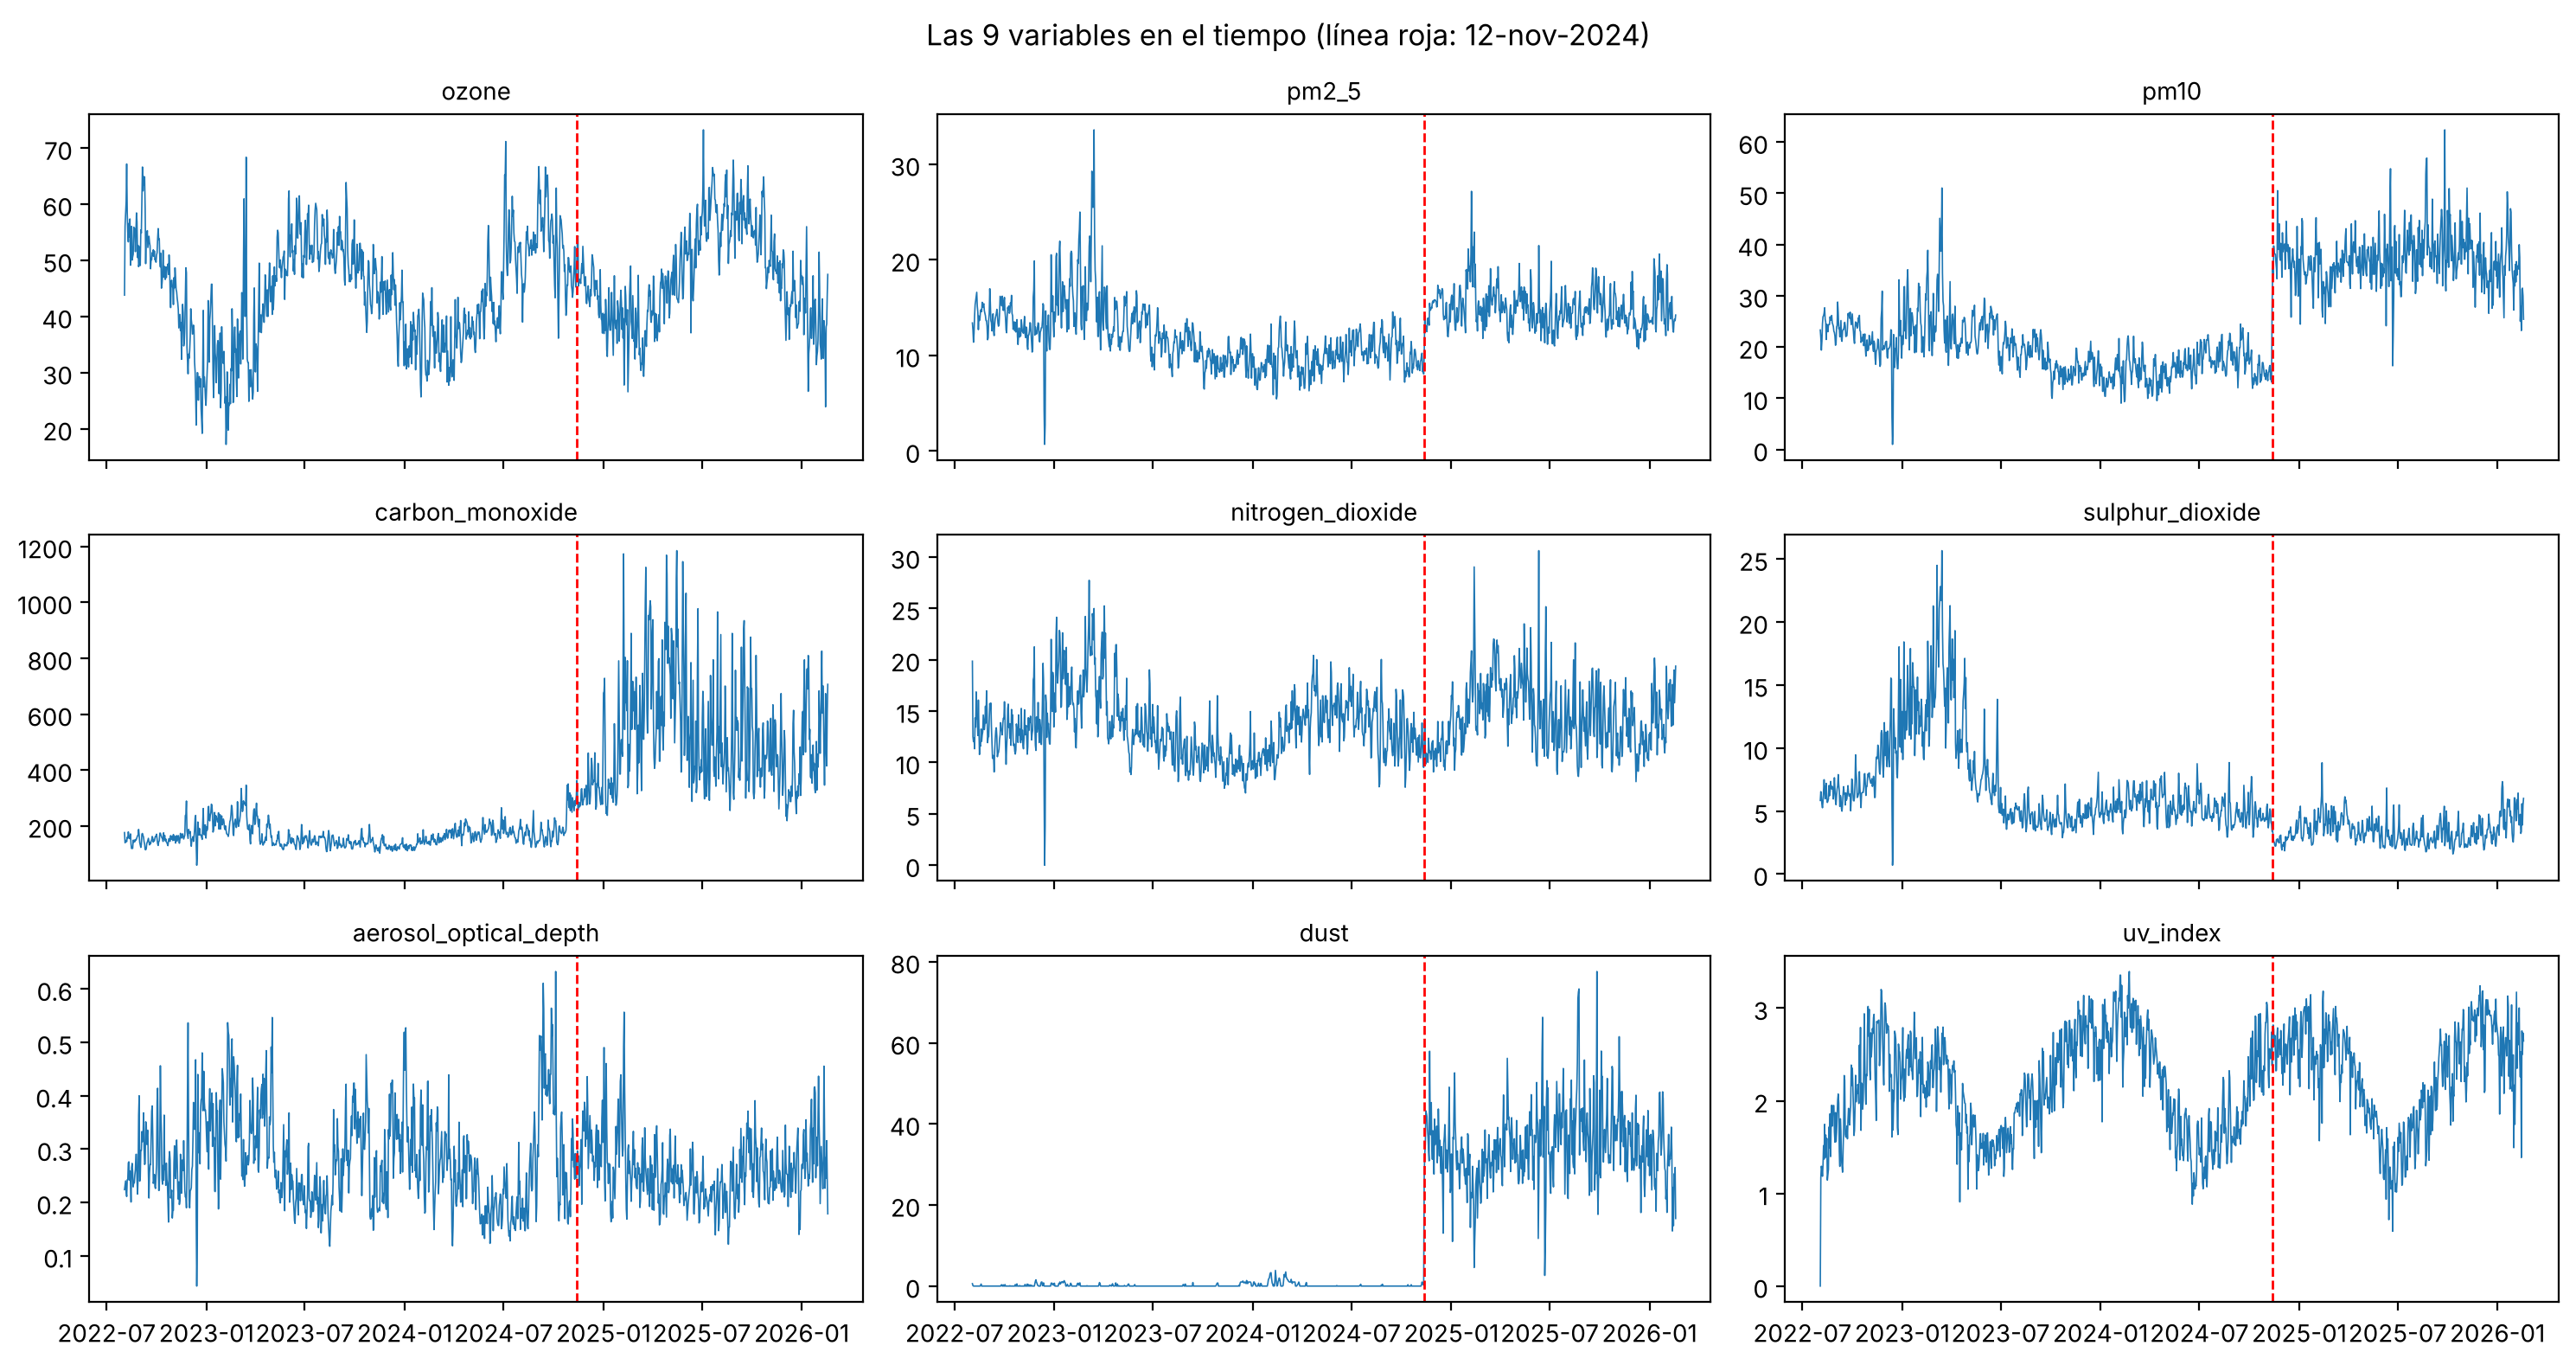

In [12]:
fig, axes = plt.subplots(3, 3, figsize=(15, 8), sharex=True)
for ax, v in zip(axes.ravel(), VARS):
    ax.plot(df.index, df[v], lw=0.6)
    ax.axvline(pd.Timestamp(QUIEBRE), color='r', ls='--', lw=1)
    ax.set_title(v, fontsize=10)
plt.suptitle('Las 9 variables en el tiempo (línea roja: 12-nov-2024)')
plt.tight_layout(); plt.savefig('fig_quiebre.png', dpi=150); plt.show()

In [13]:
# Cambio de nivel antes / después del 12-nov-2024, medido en desviaciones estándar del período anterior
antes, despues = df.loc[:'2024-11-11', VARS], df.loc[QUIEBRE:, VARS]
cambio = ((despues.mean() - antes.mean()) / antes.std()).round(2).sort_values(key=abs, ascending=False)
print(cambio)
VARS_ESTABLES = [v for v in VARS if abs(cambio[v]) <= 2]
print('\nVariables estables (cambio ≤ 2 desviaciones):', VARS_ESTABLES)
print('Variables con quiebre:', [v for v in VARS if v not in VARS_ESTABLES])

dust                     74.70
carbon_monoxide           8.63
pm10                      3.41
sulphur_dioxide          -0.96
pm2_5                     0.94
nitrogen_dioxide          0.33
uv_index                  0.31
ozone                     0.27
aerosol_optical_depth    -0.22
dtype: float64

Variables estables (cambio ≤ 2 desviaciones): ['ozone', 'pm2_5', 'nitrogen_dioxide', 'sulphur_dioxide', 'aerosol_optical_depth', 'uv_index']
Variables con quiebre: ['pm10', 'carbon_monoxide', 'dust']


**Quiebre del 12 de noviembre de 2024.** Ese día el polvo (`dust`) pasa de casi 0 a más de 25 µg/m³ y `pm10` se duplica de un día para otro; `carbon_monoxide` también cambia de nivel. No es un cambio real del aire de Lima: coincide exactamente con la fecha en que el servicio CAMS actualizó su modelo global (ciclo 49R1), que cambió la representación del polvo y los aerosoles. El dataset es un pronóstico de modelo, no una medición de estación.

**Consecuencia para el proyecto:** el quiebre cae casi al final del entrenamiento (2022–2024), así que en la prueba (2025–2026) esas tres variables toman valores que los modelos nunca vieron. Por eso se trabaja con dos conjuntos de entradas:
- **Entradas estables (principal):** las 6 variables sin quiebre (ozono, PM2.5, NO₂, SO₂, profundidad óptica de aerosoles e índice UV) → 6 × 5 + 2 = **32 entradas**.
- **Todas las entradas (comparación):** las 9 variables → 47 entradas. Sirve para medir cuánto daña el quiebre a cada modelo.

El ozono, que es lo que se predice, no presenta quiebre.

## 4. Construcción de las variables de entrada
Para cada día *t* se arma un vector con las variables atmosféricas de hoy y de hace 1, 7, 14 y 30 días, más el mes codificado con seno y coseno (2 entradas), para que diciembre y enero queden cerca. Con las 6 variables estables son **32 entradas**; con las 9, 47. La salida es el ozono del día *t + h*.

In [14]:
def construir_dataset(df, h, variables=None):
    """Devuelve (train, test) para el horizonte h. Cada fila usa solo información conocida hasta el día t."""
    variables = VARS_ESTABLES if variables is None else variables
    partes = [df[variables].shift(r).add_suffix('_r%d' % r) for r in RETRASOS]
    D = pd.concat(partes, axis=1)
    D['mes_sen'] = np.sin(2 * np.pi * df.index.month / 12)
    D['mes_cos'] = np.cos(2 * np.pi * df.index.month / 12)
    D['y'] = df['ozone'].shift(-h)                # ozono dentro de h días (lo que se quiere predecir)
    D = D.dropna()                                # se pierden los primeros 30 días y los últimos h
    fecha_objetivo = D.index + pd.Timedelta(days=h)
    train = D[fecha_objetivo <= pd.Timestamp(FIN_TRAIN)]   # el día a predecir también debe ser de 2022-2024
    test  = D[D.index > pd.Timestamp(FIN_TRAIN)]
    return train, test

for h in HORIZONTES:
    tr, te = construir_dataset(df, h)
    print('h=%2d días | train: %d filas (%s a %s) | test: %d filas (%s a %s) | entradas: %d'
          % (h, len(tr), tr.index.min().date(), tr.index.max().date(),
             len(te), te.index.min().date(), te.index.max().date(), tr.shape[1] - 1))

h= 1 días | train: 851 filas (2022-09-02 a 2024-12-30) | test: 413 filas (2025-01-01 a 2026-02-17) | entradas: 32
h= 7 días | train: 845 filas (2022-09-02 a 2024-12-24) | test: 407 filas (2025-01-01 a 2026-02-11) | entradas: 32
h=30 días | train: 822 filas (2022-09-02 a 2024-12-01) | test: 384 filas (2025-01-01 a 2026-01-19) | entradas: 32


**División cronológica.** A diferencia de los notebooks de clase (división aleatoria), aquí los datos son una serie de tiempo: si se mezclaran los días, el modelo entrenaría con días posteriores a los que debe predecir (*data leakage*). Por eso se entrena con 2022–2024 y se prueba con 2025–feb 2026, y la validación cruzada se hace con `TimeSeriesSplit` (ventana creciente: siempre se valida con días posteriores a los de entrenamiento).

## 5. Definición de las clases (condición ambiental)
Las clases se definen con los percentiles 50 y 75 del ozono **del período de entrenamiento** y se aplican sin cambios a la prueba:
- **Favorable:** ozono ≤ P50
- **Moderado:** P50 < ozono ≤ P75
- **Desfavorable:** ozono > P75

Son umbrales propios (relativos al historial de Lima), no límites normativos.

In [15]:
ozono_train = df.loc[:FIN_TRAIN, 'ozone']
U1, U2 = ozono_train.quantile(0.50), ozono_train.quantile(0.75)
print('Umbrales: P50 = %.1f µg/m³ | P75 = %.1f µg/m³' % (U1, U2))

def a_clase(valores):
    """Convierte ozono (µg/m³) en clase 0=Favorable, 1=Moderado, 2=Desfavorable."""
    return np.digitize(np.asarray(valores), [U1, U2], right=True)

dist = pd.DataFrame({
    'Entrenamiento': pd.Series(a_clase(df.loc[:FIN_TRAIN, 'ozone'])).value_counts(normalize=True).sort_index(),
    'Prueba': pd.Series(a_clase(df.loc['2025':, 'ozone'])).value_counts(normalize=True).sort_index()})
dist.index = CLASES
dist.round(2)

Umbrales: P50 = 45.5 µg/m³ | P75 = 51.4 µg/m³


,Entrenamiento,Prueba
Favorable,0.50,0.46
Moderado,0.25,0.20
Desfavorable,0.25,0.34


## 6. Referencias de comparación (baseline)
Un modelo solo es útil si supera a estas dos reglas simples:
- **Persistencia:** el ozono dentro de *h* días será igual al de hoy.
- **Media mensual:** el ozono será el promedio histórico (entrenamiento) del mes del día a predecir.

In [16]:
MEDIA_MES = ozono_train.groupby(ozono_train.index.month).mean()

def pred_persistencia(test):
    return test['ozone_r0'].values

def pred_media_mensual(test, h):
    meses = (test.index + pd.Timedelta(days=h)).month
    return MEDIA_MES.loc[meses].values

def metricas_reg(y, p):
    return {'MAE': mean_absolute_error(y, p), 'RMSE': mean_squared_error(y, p) ** 0.5, 'R2': r2_score(y, p)}

def metricas_clf(y, p):
    return {'BalAcc': balanced_accuracy_score(y, p), 'F1macro': f1_score(y, p, average='macro')}

## 7. Regresión: pronóstico del ozono (µg/m³)
### 7.1 Evaluación de algoritmos en validación cruzada temporal
Igual que en clase, primero se evalúa un pool de pipelines (escalador + algoritmo) solo con datos de entrenamiento. El escalado va dentro del pipeline para no filtrar información. Métrica: `neg_mean_absolute_error` (a mayor valor, mejor).

--- Horizonte 1 día(s)
LinearReg  -5.114 (4.435)
Ridge      -4.896 (4.004)
KNN5       -4.905 (1.068)


KNN15      -4.699 (1.091)


Arbol      -5.324 (1.391)


Arbol_p5   -4.092 (1.375)
--- Horizonte 7 día(s)
LinearReg  -6.039 (1.491)


Ridge      -5.847 (1.222)


KNN5       -5.501 (0.851)
KNN15      -5.154 (0.935)


Arbol      -8.379 (4.844)
Arbol_p5   -7.787 (5.040)
--- Horizonte 30 día(s)


LinearReg  -10.979 (11.003)
Ridge      -10.136 (9.414)


KNN5       -6.267 (1.777)
KNN15      -6.081 (1.980)


Arbol      -7.557 (1.807)
Arbol_p5   -6.736 (1.441)


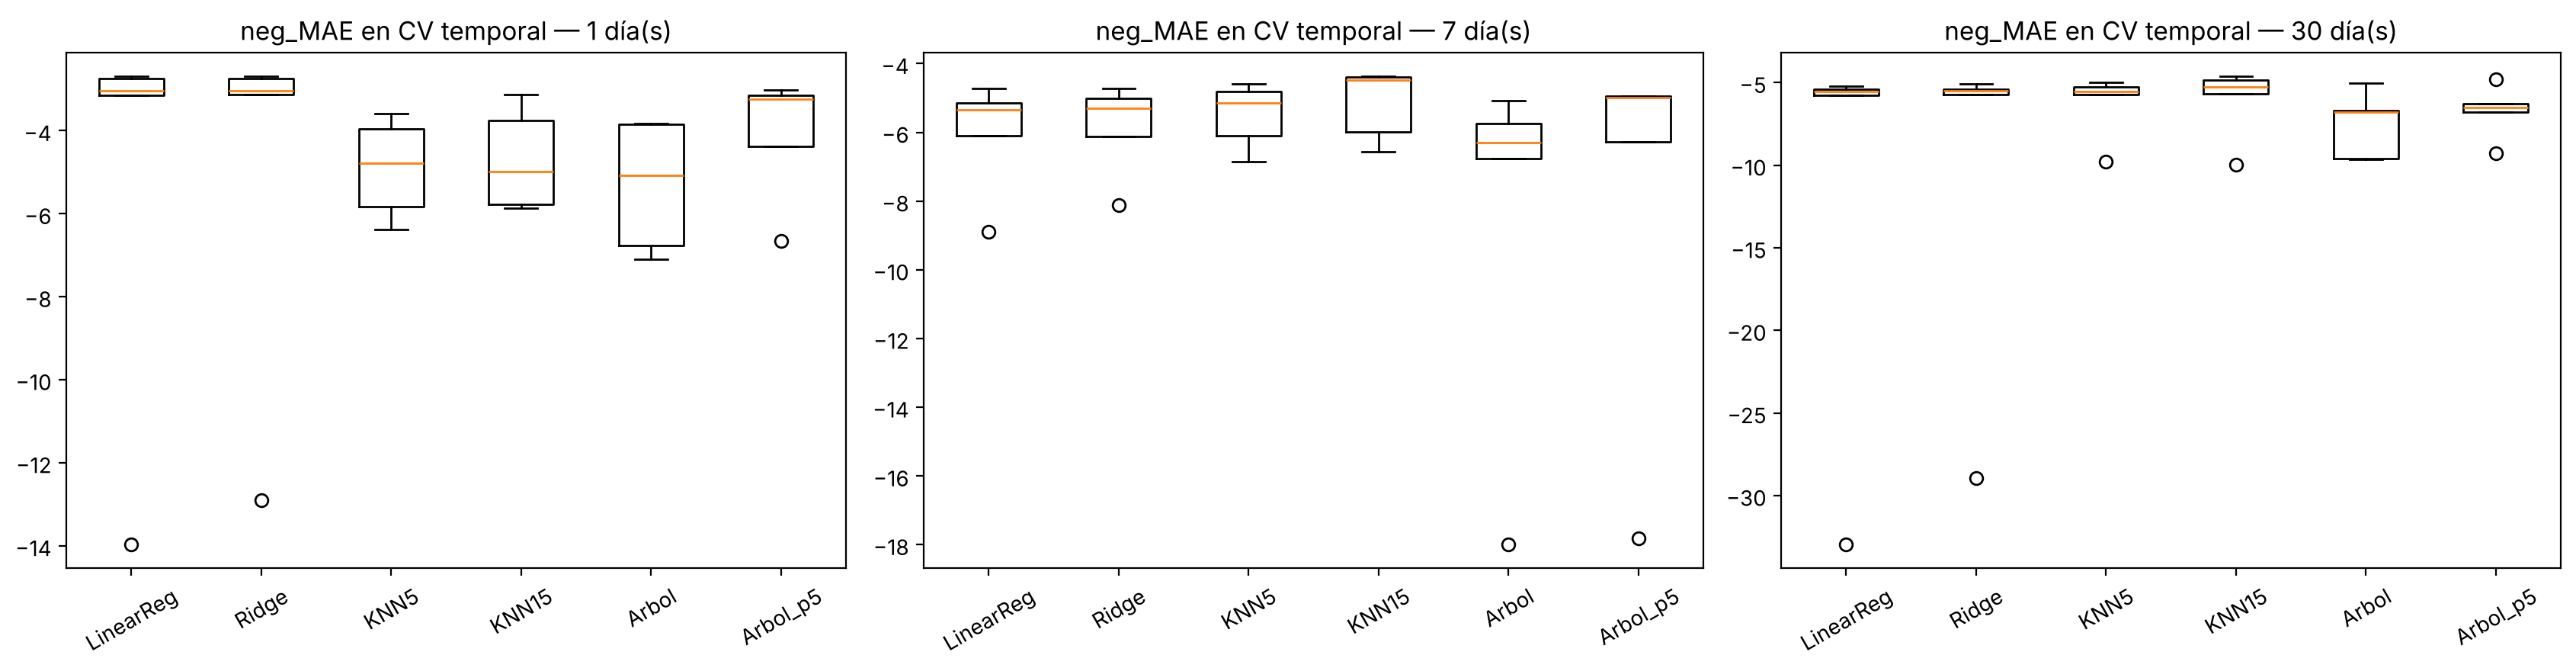

In [17]:
def pool_regresion():
    return [('LinearReg', make_pipeline(StandardScaler(), LinearRegression())),
            ('Ridge',     make_pipeline(StandardScaler(), Ridge())),
            ('KNN5',      make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5))),
            ('KNN15',     make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=15))),
            ('Arbol',     make_pipeline(StandardScaler(), DecisionTreeRegressor(random_state=SEED))),
            ('Arbol_p5',  make_pipeline(StandardScaler(), DecisionTreeRegressor(max_depth=5, random_state=SEED)))]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, h in zip(axes, HORIZONTES):
    train, _ = construir_dataset(df, h)
    X_train, y_train = train.drop(columns='y'), train['y']
    tscv = TimeSeriesSplit(n_splits=5, gap=h)      # gap=h: deja h días entre entrenamiento y validación
    results, names = [], []
    print('--- Horizonte %d día(s)' % h)
    for nombre, pipe in pool_regresion():
        cv = cross_val_score(pipe, X_train, y_train, cv=tscv, scoring='neg_mean_absolute_error')
        results.append(cv); names.append(nombre)
        print('%-10s %.3f (%.3f)' % (nombre, cv.mean(), cv.std()))
    ax.boxplot(results); ax.set_xticklabels(names, rotation=30)
    ax.set_title('neg_MAE en CV temporal — %d día(s)' % h)
plt.tight_layout()
plt.savefig('fig_cv_regresion.png', dpi=150)
plt.show()

### 7.2 Optimización de hiperparámetros (búsqueda en grilla)
Se ajustan los hiperparámetros de cada familia con `GridSearchCV` y la misma validación temporal. La regresión lineal se prueba sin regularización y con regularización L2 (Ridge), porque las 47 entradas están muy correlacionadas entre sí.

In [18]:
GRILLAS_REG = {
    'Regresión lineal': (make_pipeline(StandardScaler(), LinearRegression()), {}),
    'Regresión lineal (Ridge)': (make_pipeline(StandardScaler(), Ridge()),
                                 {'ridge__alpha': [0.1, 1, 10, 100, 300, 1000]}),
    'Árbol de decisión': (make_pipeline(StandardScaler(), DecisionTreeRegressor(random_state=SEED)),
                          {'decisiontreeregressor__max_depth': [3, 5, 10],
                           'decisiontreeregressor__min_samples_leaf': [5, 10, 20, 40]}),
    'KNN': (make_pipeline(StandardScaler(), KNeighborsRegressor()),
            {'kneighborsregressor__n_neighbors': [3, 5, 10, 15, 20, 30, 50],
             'kneighborsregressor__weights': ['uniform', 'distance']}),
}

def ajustar_grillas(grillas, X_train, y_train, h, scoring):
    """Ajusta cada familia con GridSearchCV temporal y devuelve los mejores modelos (reentrenados con todo train)."""
    tscv = TimeSeriesSplit(n_splits=5, gap=h)
    mejores = {}
    for nombre, (pipe, grid) in grillas.items():
        gs = GridSearchCV(pipe, grid, cv=tscv, scoring=scoring)
        gs.fit(X_train, y_train)
        mejores[nombre] = gs
        print('  %-26s CV=%.3f  %s' % (nombre, gs.best_score_, gs.best_params_))
    return mejores

### 7.3 Red neuronal MLP (Keras)
Se comparan dos arquitecturas, como en clase: una pequeña (1 capa oculta de 16 neuronas) y una mayor (2 capas ocultas de 64 y 32). Activación ReLU, optimizador Adam y pérdida MSE. Para elegir, se separa el último 20 % del entrenamiento como validación (respetando el orden del tiempo) y se usa *early stopping*. Luego la mejor arquitectura se reentrena con todo el entrenamiento.

Como el resultado de una red depende de sus pesos iniciales, el modelo final se entrena 5 veces con semillas distintas y la predicción reportada es el **promedio de las 5 redes**.

In [19]:
ARQUITECTURAS = {'MLP(16)': [16], 'MLP(64-32)': [64, 32]}

def crear_mlp(capas, n_entradas, n_salidas=1):
    """n_salidas=1 -> regresión (salida lineal). n_salidas>1 -> clasificación (softmax)."""
    modelo = Sequential([Input(shape=(n_entradas,))])
    for n in capas:
        modelo.add(Dense(n, activation='relu'))
    if n_salidas == 1:
        modelo.add(Dense(1))
        modelo.compile(optimizer=keras.optimizers.Adam(0.001), loss='mse', metrics=['mae'])
    else:
        modelo.add(Dense(n_salidas, activation='softmax'))
        modelo.compile(optimizer=keras.optimizers.Adam(0.001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return modelo

def preparar_mlp(X_train, X_test):
    """Separa validación (último 20% de train) y estandariza ajustando el escalador solo con datos de entrenamiento."""
    corte = int(len(X_train) * 0.8)
    sc_val = StandardScaler().fit(X_train.iloc[:corte])
    sc_fin = StandardScaler().fit(X_train)
    return corte, sc_val, sc_fin

def entrenar_mlp(X_train, y_train, X_test, tarea, pesos_clase=None, n_semillas=5, verbose=True):
    """Elige arquitectura en validación temporal, reentrena con todo train y predice en test (promedio de semillas).
    tarea: 'reg' o 'clf'. Devuelve predicciones por semilla, historias de validación y nombre de la mejor arquitectura."""
    corte, sc_val, sc_fin = preparar_mlp(X_train, X_test)
    Xa, Xv = sc_val.transform(X_train.iloc[:corte]), sc_val.transform(X_train.iloc[corte:])
    ya, yv = y_train.values[:corte], y_train.values[corte:]
    n_sal = 1 if tarea == 'reg' else 3
    if tarea == 'reg':                       # se estandariza también el target para estabilizar el entrenamiento
        mu, sd = ya.mean(), ya.std()
        ya_, yv_ = (ya - mu) / sd, (yv - mu) / sd
    else:
        ya_, yv_ = ya, yv
    historias, puntaje, epocas = {}, {}, {}
    for nombre, capas in ARQUITECTURAS.items():
        tf.keras.utils.set_random_seed(SEED)
        m = crear_mlp(capas, Xa.shape[1], n_sal)
        es = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)
        hist = m.fit(Xa, ya_, validation_data=(Xv, yv_), epochs=300, batch_size=32,
                     callbacks=[es], class_weight=pesos_clase, verbose=0)
        historias[nombre] = hist.history
        puntaje[nombre] = min(hist.history['val_loss'])
        epocas[nombre] = int(np.argmin(hist.history['val_loss'])) + 1
        if verbose: print('  %-11s val_loss=%.4f (mejor época: %d)' % (nombre, puntaje[nombre], epocas[nombre]))
    mejor = min(puntaje, key=puntaje.get)
    # Entrenamiento final con todo train, usando el número de épocas hallado en validación
    Xt, Xp = sc_fin.transform(X_train), sc_fin.transform(X_test)
    yt = y_train.values
    if tarea == 'reg':
        mu, sd = yt.mean(), yt.std(); yt_ = (yt - mu) / sd
    else:
        yt_ = yt
    preds = []
    for s in range(n_semillas):
        tf.keras.utils.set_random_seed(SEED + s)
        m = crear_mlp(ARQUITECTURAS[mejor], Xt.shape[1], n_sal)
        m.fit(Xt, yt_, epochs=epocas[mejor], batch_size=32, class_weight=pesos_clase, verbose=0)
        p = m.predict(Xp, verbose=0)
        preds.append(p.flatten() * sd + mu if tarea == 'reg' else p)
    return preds, historias, mejor

def plot_curvas(historias, titulo):
    """Curvas de aprendizaje (loss) en entrenamiento y validación para cada arquitectura."""
    fig, axes = plt.subplots(1, len(historias), figsize=(6 * len(historias), 3.8))
    for ax, (nombre, hst) in zip(np.atleast_1d(axes), historias.items()):
        ax.plot(hst['loss'], label='Entrenamiento'); ax.plot(hst['val_loss'], '--', label='Validación')
        ax.set_title('%s — %s' % (titulo, nombre)); ax.set_xlabel('Épocas'); ax.set_ylabel('Loss'); ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

### 7.4 Entrenamiento final y evaluación en el conjunto de prueba
El conjunto de prueba (2025–feb 2026) se usa una sola vez, con los modelos ya elegidos.

=== Horizonte 1 día(s)
  Regresión lineal           CV=-5.114  {}


  Regresión lineal (Ridge)   CV=-3.536  {'ridge__alpha': 100}


  Árbol de decisión          CV=-3.527  {'decisiontreeregressor__max_depth': 5, 'decisiontreeregressor__min_samples_leaf': 20}


  KNN                        CV=-4.547  {'kneighborsregressor__n_neighbors': 50, 'kneighborsregressor__weights': 'distance'}


  MLP(16)     val_loss=0.2097 (mejor época: 116)


  MLP(64-32)  val_loss=0.2447 (mejor época: 8)


  MLP elegido: MLP(16) | MAE en test por semilla: 4.25 ± 0.36


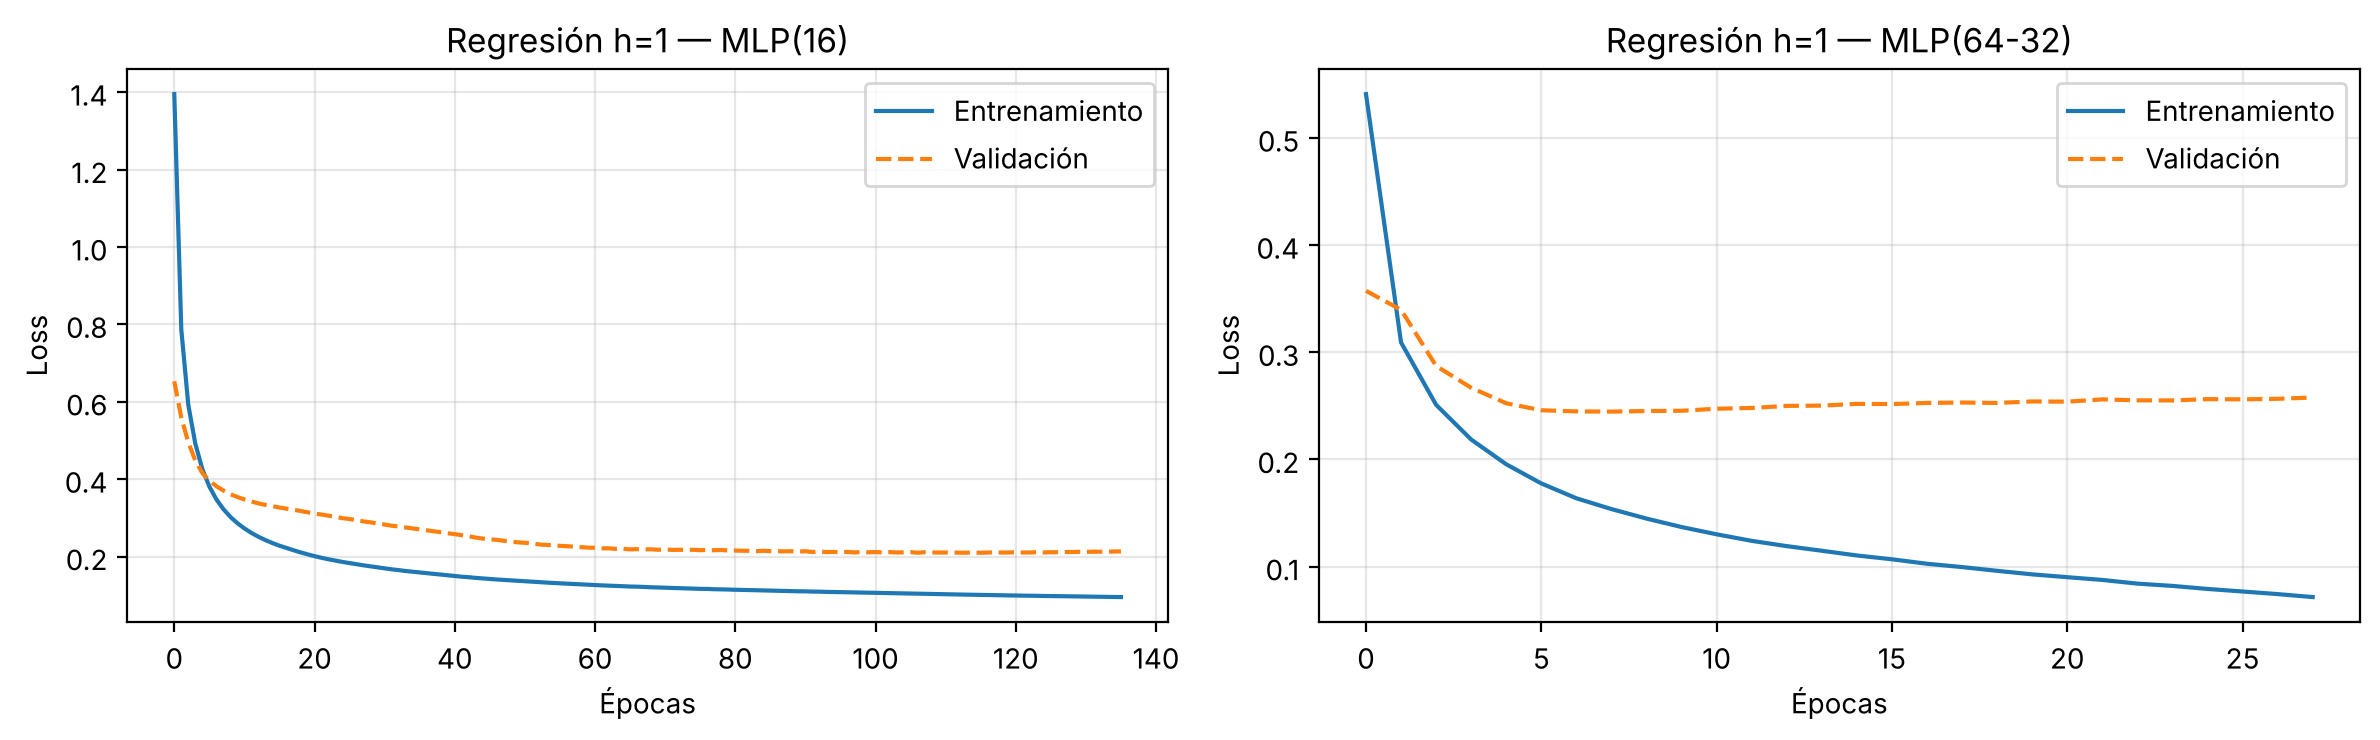

=== Horizonte 7 día(s)


  Regresión lineal           CV=-6.039  {}


  Regresión lineal (Ridge)   CV=-4.790  {'ridge__alpha': 300}


  Árbol de decisión          CV=-6.013  {'decisiontreeregressor__max_depth': 3, 'decisiontreeregressor__min_samples_leaf': 5}


  KNN                        CV=-4.913  {'kneighborsregressor__n_neighbors': 50, 'kneighborsregressor__weights': 'uniform'}


  MLP(16)     val_loss=0.4608 (mejor época: 8)


  MLP(64-32)  val_loss=0.3676 (mejor época: 8)


  MLP elegido: MLP(64-32) | MAE en test por semilla: 4.52 ± 0.12


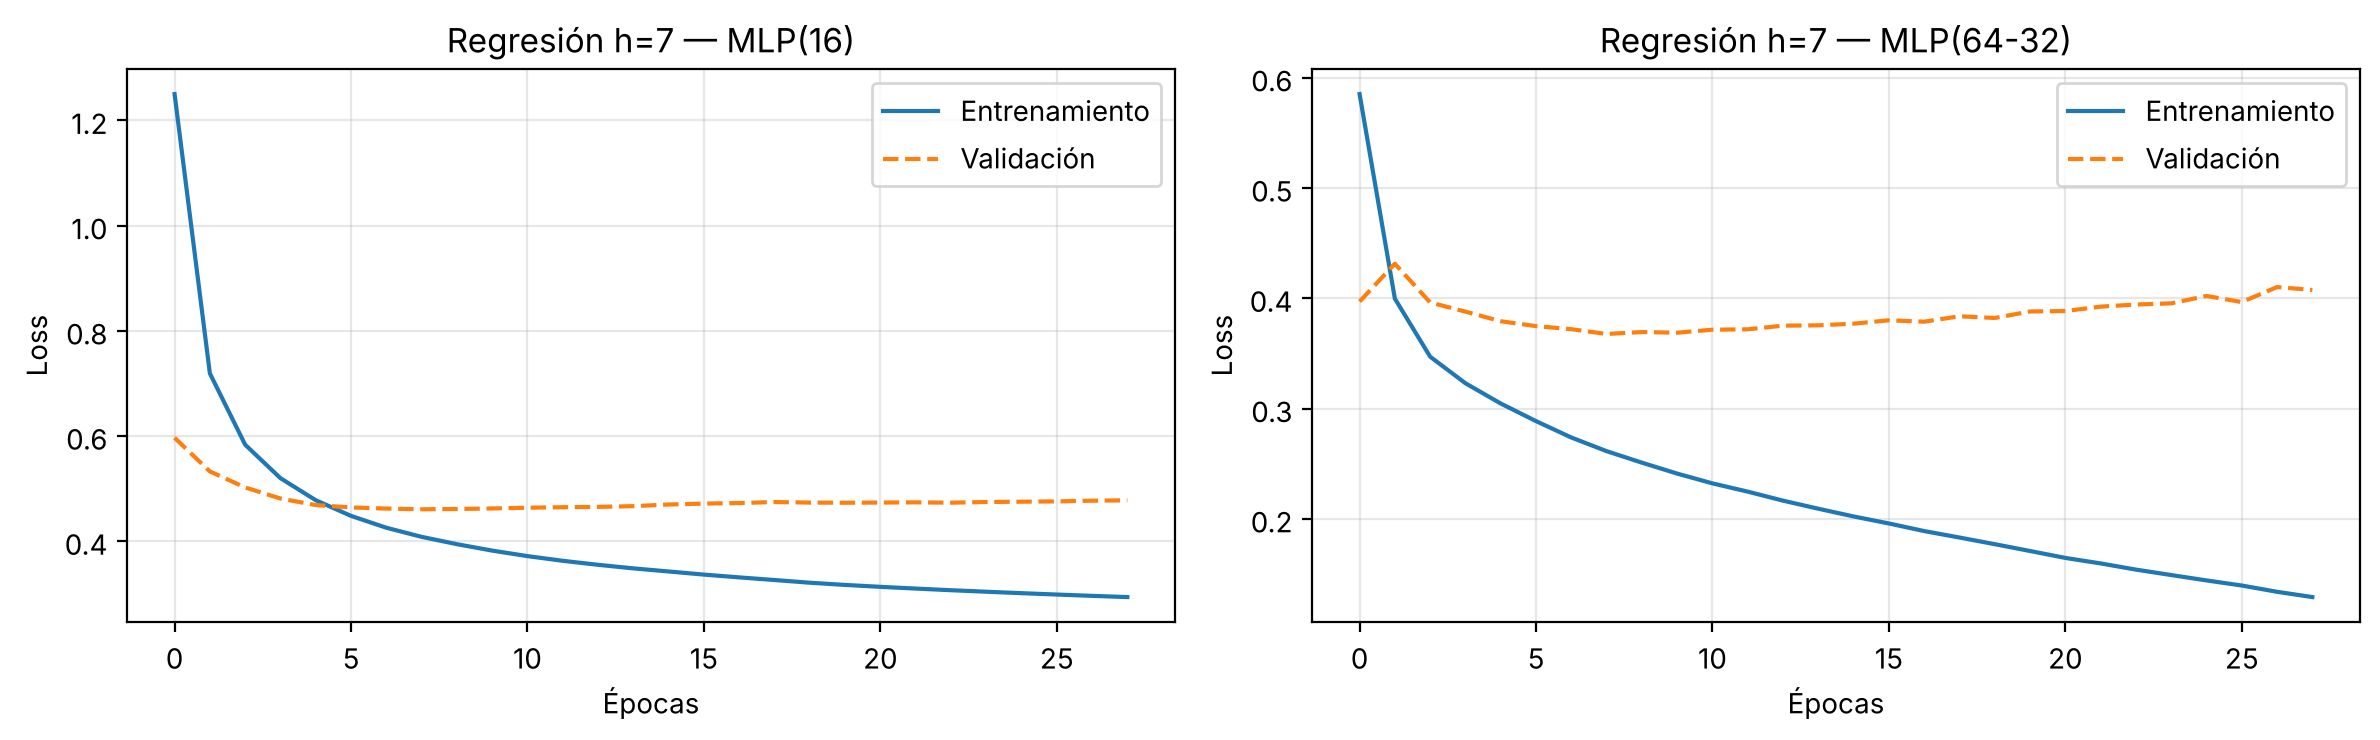

=== Horizonte 30 día(s)


  Regresión lineal           CV=-10.979  {}


  Regresión lineal (Ridge)   CV=-5.154  {'ridge__alpha': 100}


  Árbol de decisión          CV=-6.525  {'decisiontreeregressor__max_depth': 10, 'decisiontreeregressor__min_samples_leaf': 5}


  KNN                        CV=-5.862  {'kneighborsregressor__n_neighbors': 50, 'kneighborsregressor__weights': 'distance'}


  MLP(16)     val_loss=0.3860 (mejor época: 9)


  MLP(64-32)  val_loss=0.4128 (mejor época: 8)


  MLP elegido: MLP(16) | MAE en test por semilla: 6.27 ± 0.59


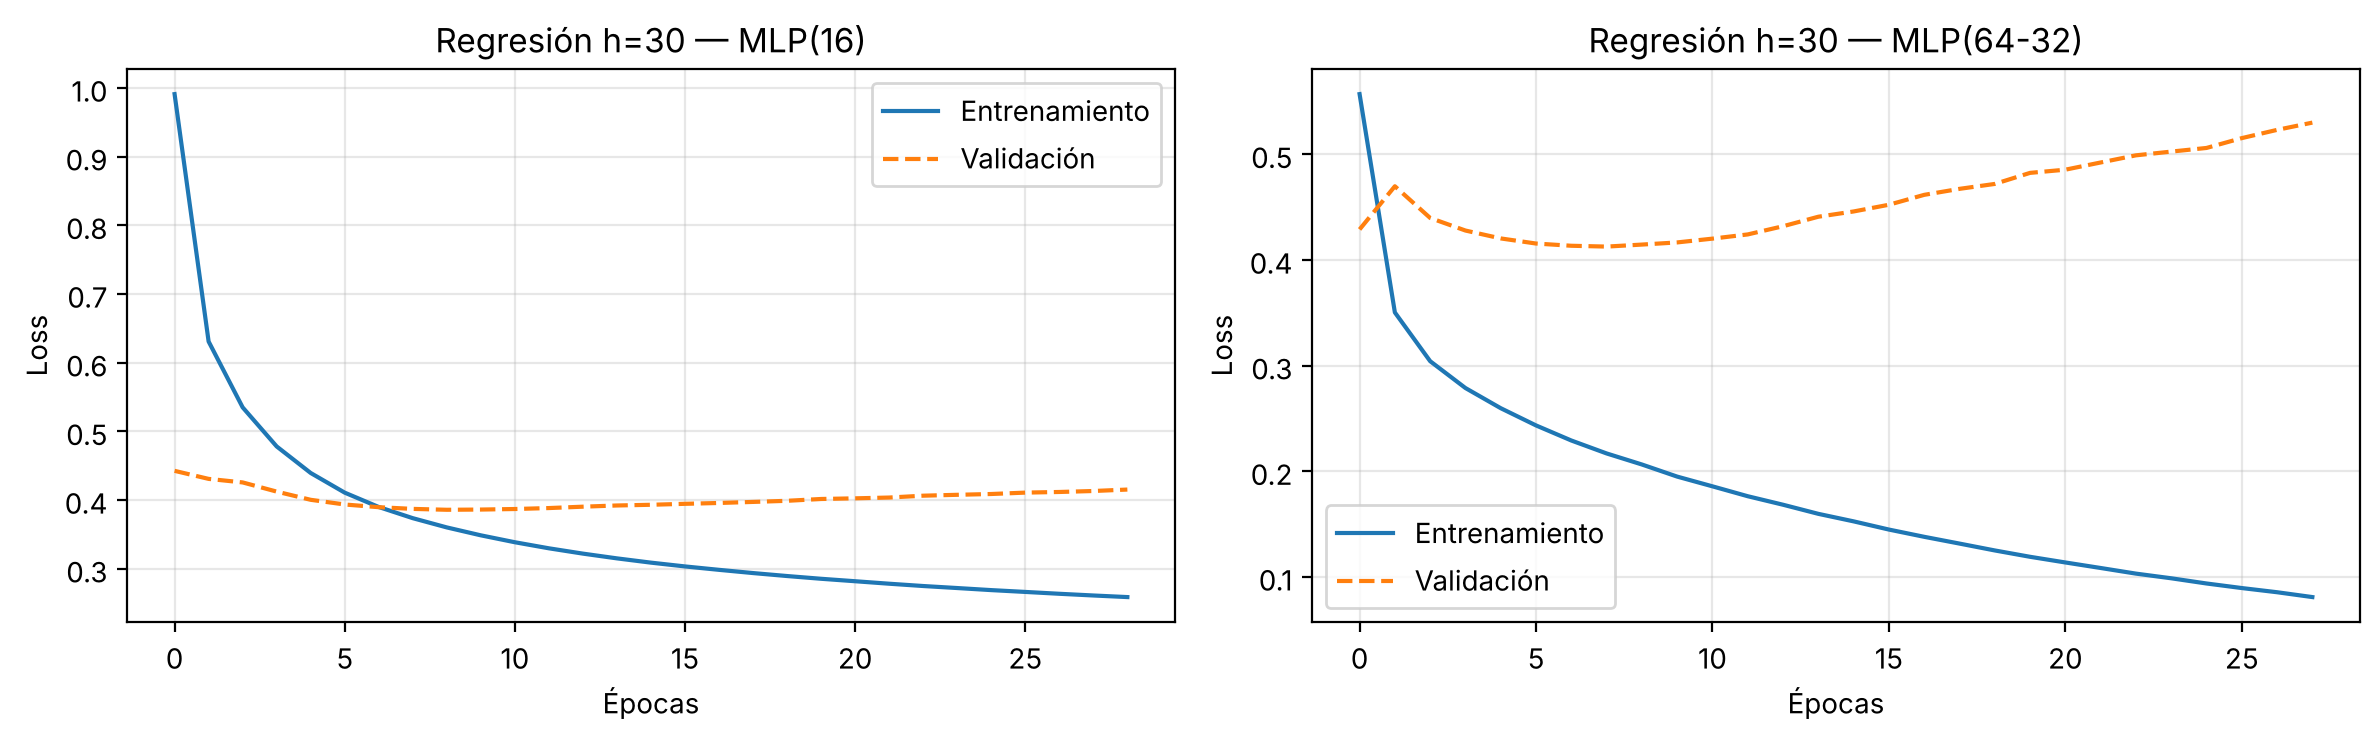

In [20]:
def experimento_regresion(variables, mostrar_curvas=True):
    """Ajusta y evalúa todos los modelos de regresión para los 3 horizontes con el conjunto de variables dado."""
    res, pred, modelos = [], {}, {}
    for h in HORIZONTES:
        print('=== Horizonte %d día(s)' % h)
        train, test = construir_dataset(df, h, variables)
        X_train, y_train = train.drop(columns='y'), train['y']
        X_test,  y_test  = test.drop(columns='y'),  test['y']
        pred[h] = {'real': y_test}
        # Referencias
        pred[h]['Persistencia']  = pred_persistencia(test)
        pred[h]['Media mensual'] = pred_media_mensual(test, h)
        # Modelos clásicos
        mejores = ajustar_grillas(GRILLAS_REG, X_train, y_train, h, 'neg_mean_absolute_error')
        modelos[h] = mejores
        for nombre, gs in mejores.items():
            pred[h][nombre] = gs.predict(X_test)
        # MLP
        preds, historias, mejor = entrenar_mlp(X_train, y_train, X_test, 'reg')
        pred[h]['MLP'] = np.mean(preds, axis=0)
        mae_semillas = [mean_absolute_error(y_test, p) for p in preds]
        print('  MLP elegido: %s | MAE en test por semilla: %.2f ± %.2f' % (mejor, np.mean(mae_semillas), np.std(mae_semillas)))
        if mostrar_curvas: plot_curvas(historias, 'Regresión h=%d' % h)
        for nombre, p in pred[h].items():
            if nombre != 'real':
                res.append({'Modelo': nombre, 'h': h, **metricas_reg(y_test, p)})
    return pd.DataFrame(res), pred, modelos

# Experimento principal: entradas estables (32)
res_reg, pred_reg, modelos_reg = experimento_regresion(VARS_ESTABLES)

### 7.5 Cuadro comparativo de regresión (conjunto de prueba)
En cada columna el mejor valor es el **MAE más bajo** (error medio en µg/m³).

In [21]:
ORDEN = ['Persistencia', 'Media mensual', 'Regresión lineal', 'Regresión lineal (Ridge)', 'Árbol de decisión', 'KNN', 'MLP']
tabla_mae = res_reg.pivot(index='Modelo', columns='h', values='MAE').loc[ORDEN]
tabla_mae.columns = ['MAE 1 día', 'MAE 7 días', 'MAE 30 días']
tabla_mae.style.format('{:.2f}').highlight_min(axis=0, props='font-weight:bold; background-color:#d9ead3')

,MAE 1 día,MAE 7 días,MAE 30 días
Modelo,,,
Persistencia,3.46,5.42,6.27
Media mensual,5.29,5.30,5.33
Regresión lineal,3.43,4.62,9.82
Regresión lineal (Ridge),3.36,4.27,6.96
Árbol de decisión,3.64,6.29,5.68
KNN,4.55,4.90,5.54
MLP,3.68,4.22,5.77


In [22]:
tabla_det = res_reg.pivot(index='Modelo', columns='h', values=['RMSE', 'R2']).loc[ORDEN].round(3)
tabla_det

RMSE                    R2              
h                            1      7       30     1      7      30
Modelo                                                             
Persistencia              4.512  6.800   7.733  0.754  0.441  0.277
Media mensual             6.546  6.564   6.608  0.482  0.479  0.472
Regresión lineal          4.347  5.720  11.028  0.771  0.604 -0.470
Regresión lineal (Ridge)  4.253  5.389   8.274  0.781  0.649  0.173
Árbol de decisión         4.619  7.907   7.087  0.742  0.244  0.393
KNN                       5.643  6.116   6.774  0.615  0.548  0.445
MLP                       4.786  5.321   7.005  0.723  0.658  0.407

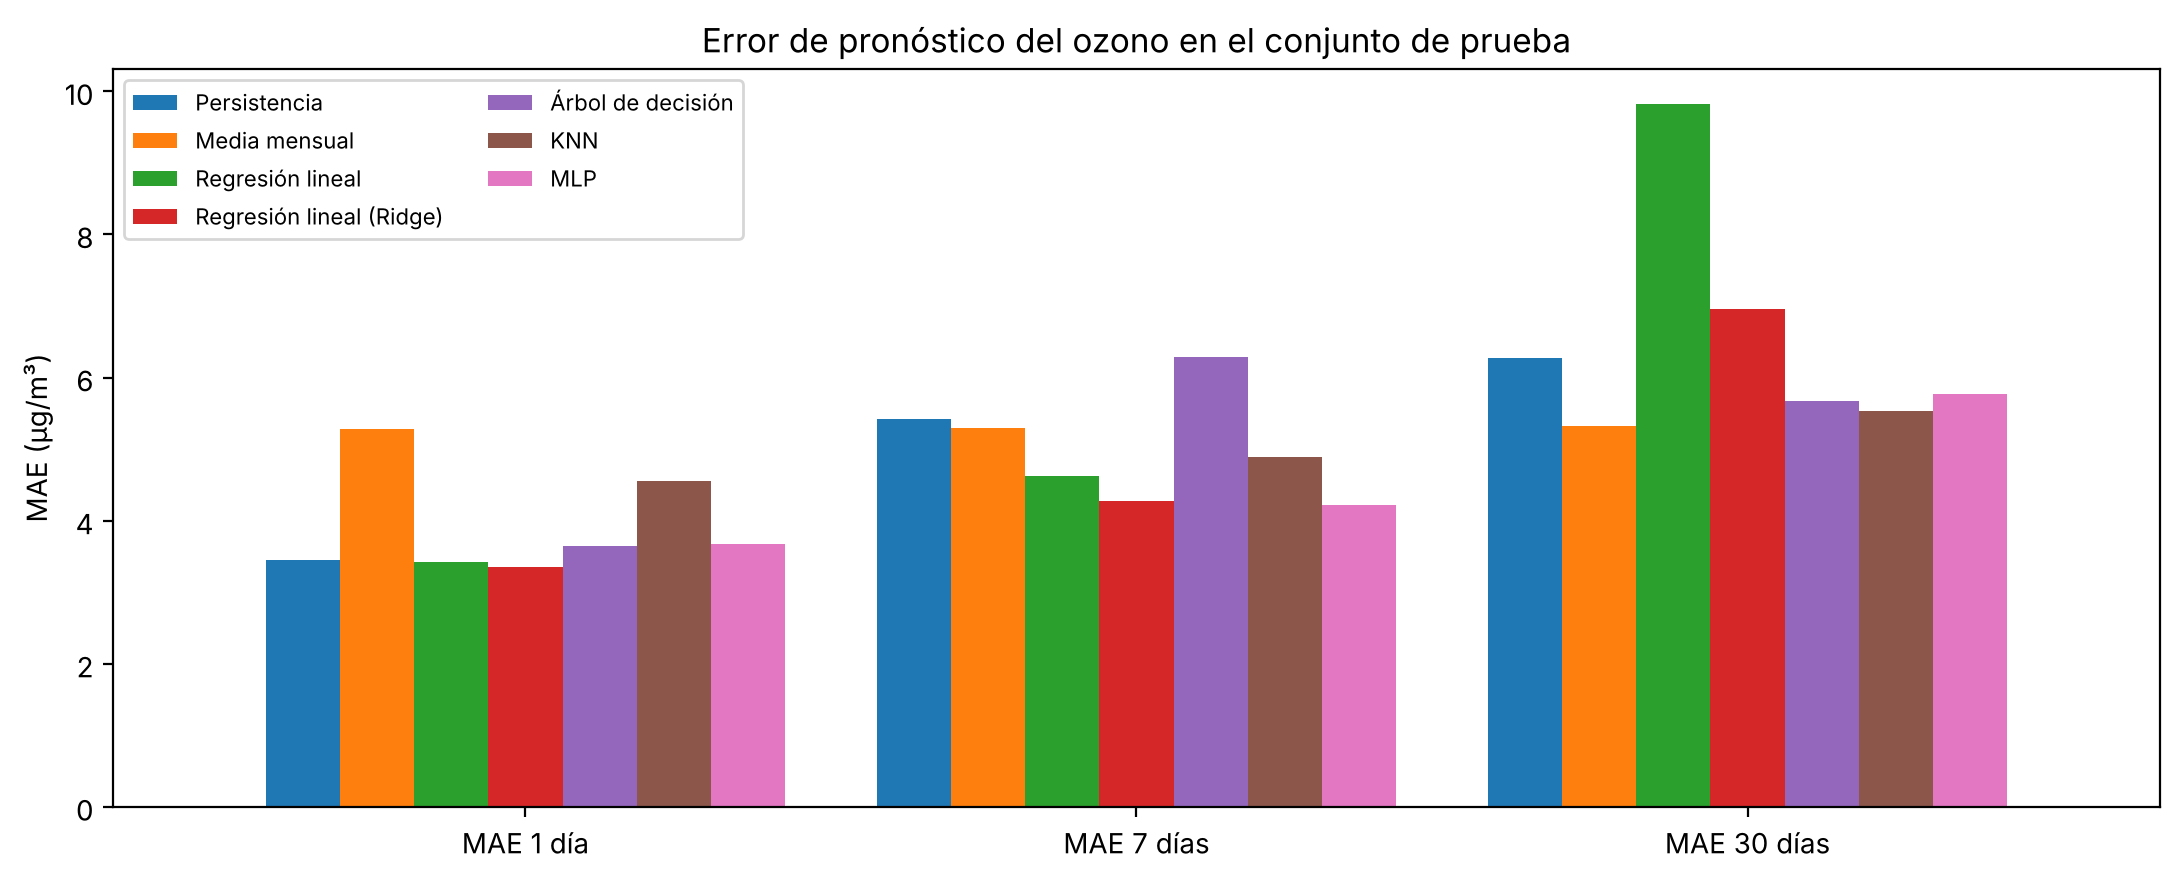

In [23]:
# Gráfico: MAE por modelo y horizonte
ax = tabla_mae.T.plot(kind='bar', figsize=(11, 4.5), width=0.85, rot=0)
ax.set_ylabel('MAE (µg/m³)'); ax.set_title('Error de pronóstico del ozono en el conjunto de prueba')
ax.legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.savefig('fig_mae.png', dpi=150); plt.show()

### 7.6 Valores reales vs. predichos

Mejor modelo por horizonte: {1: 'Regresión lineal (Ridge)', 7: 'MLP', 30: 'Media mensual'}


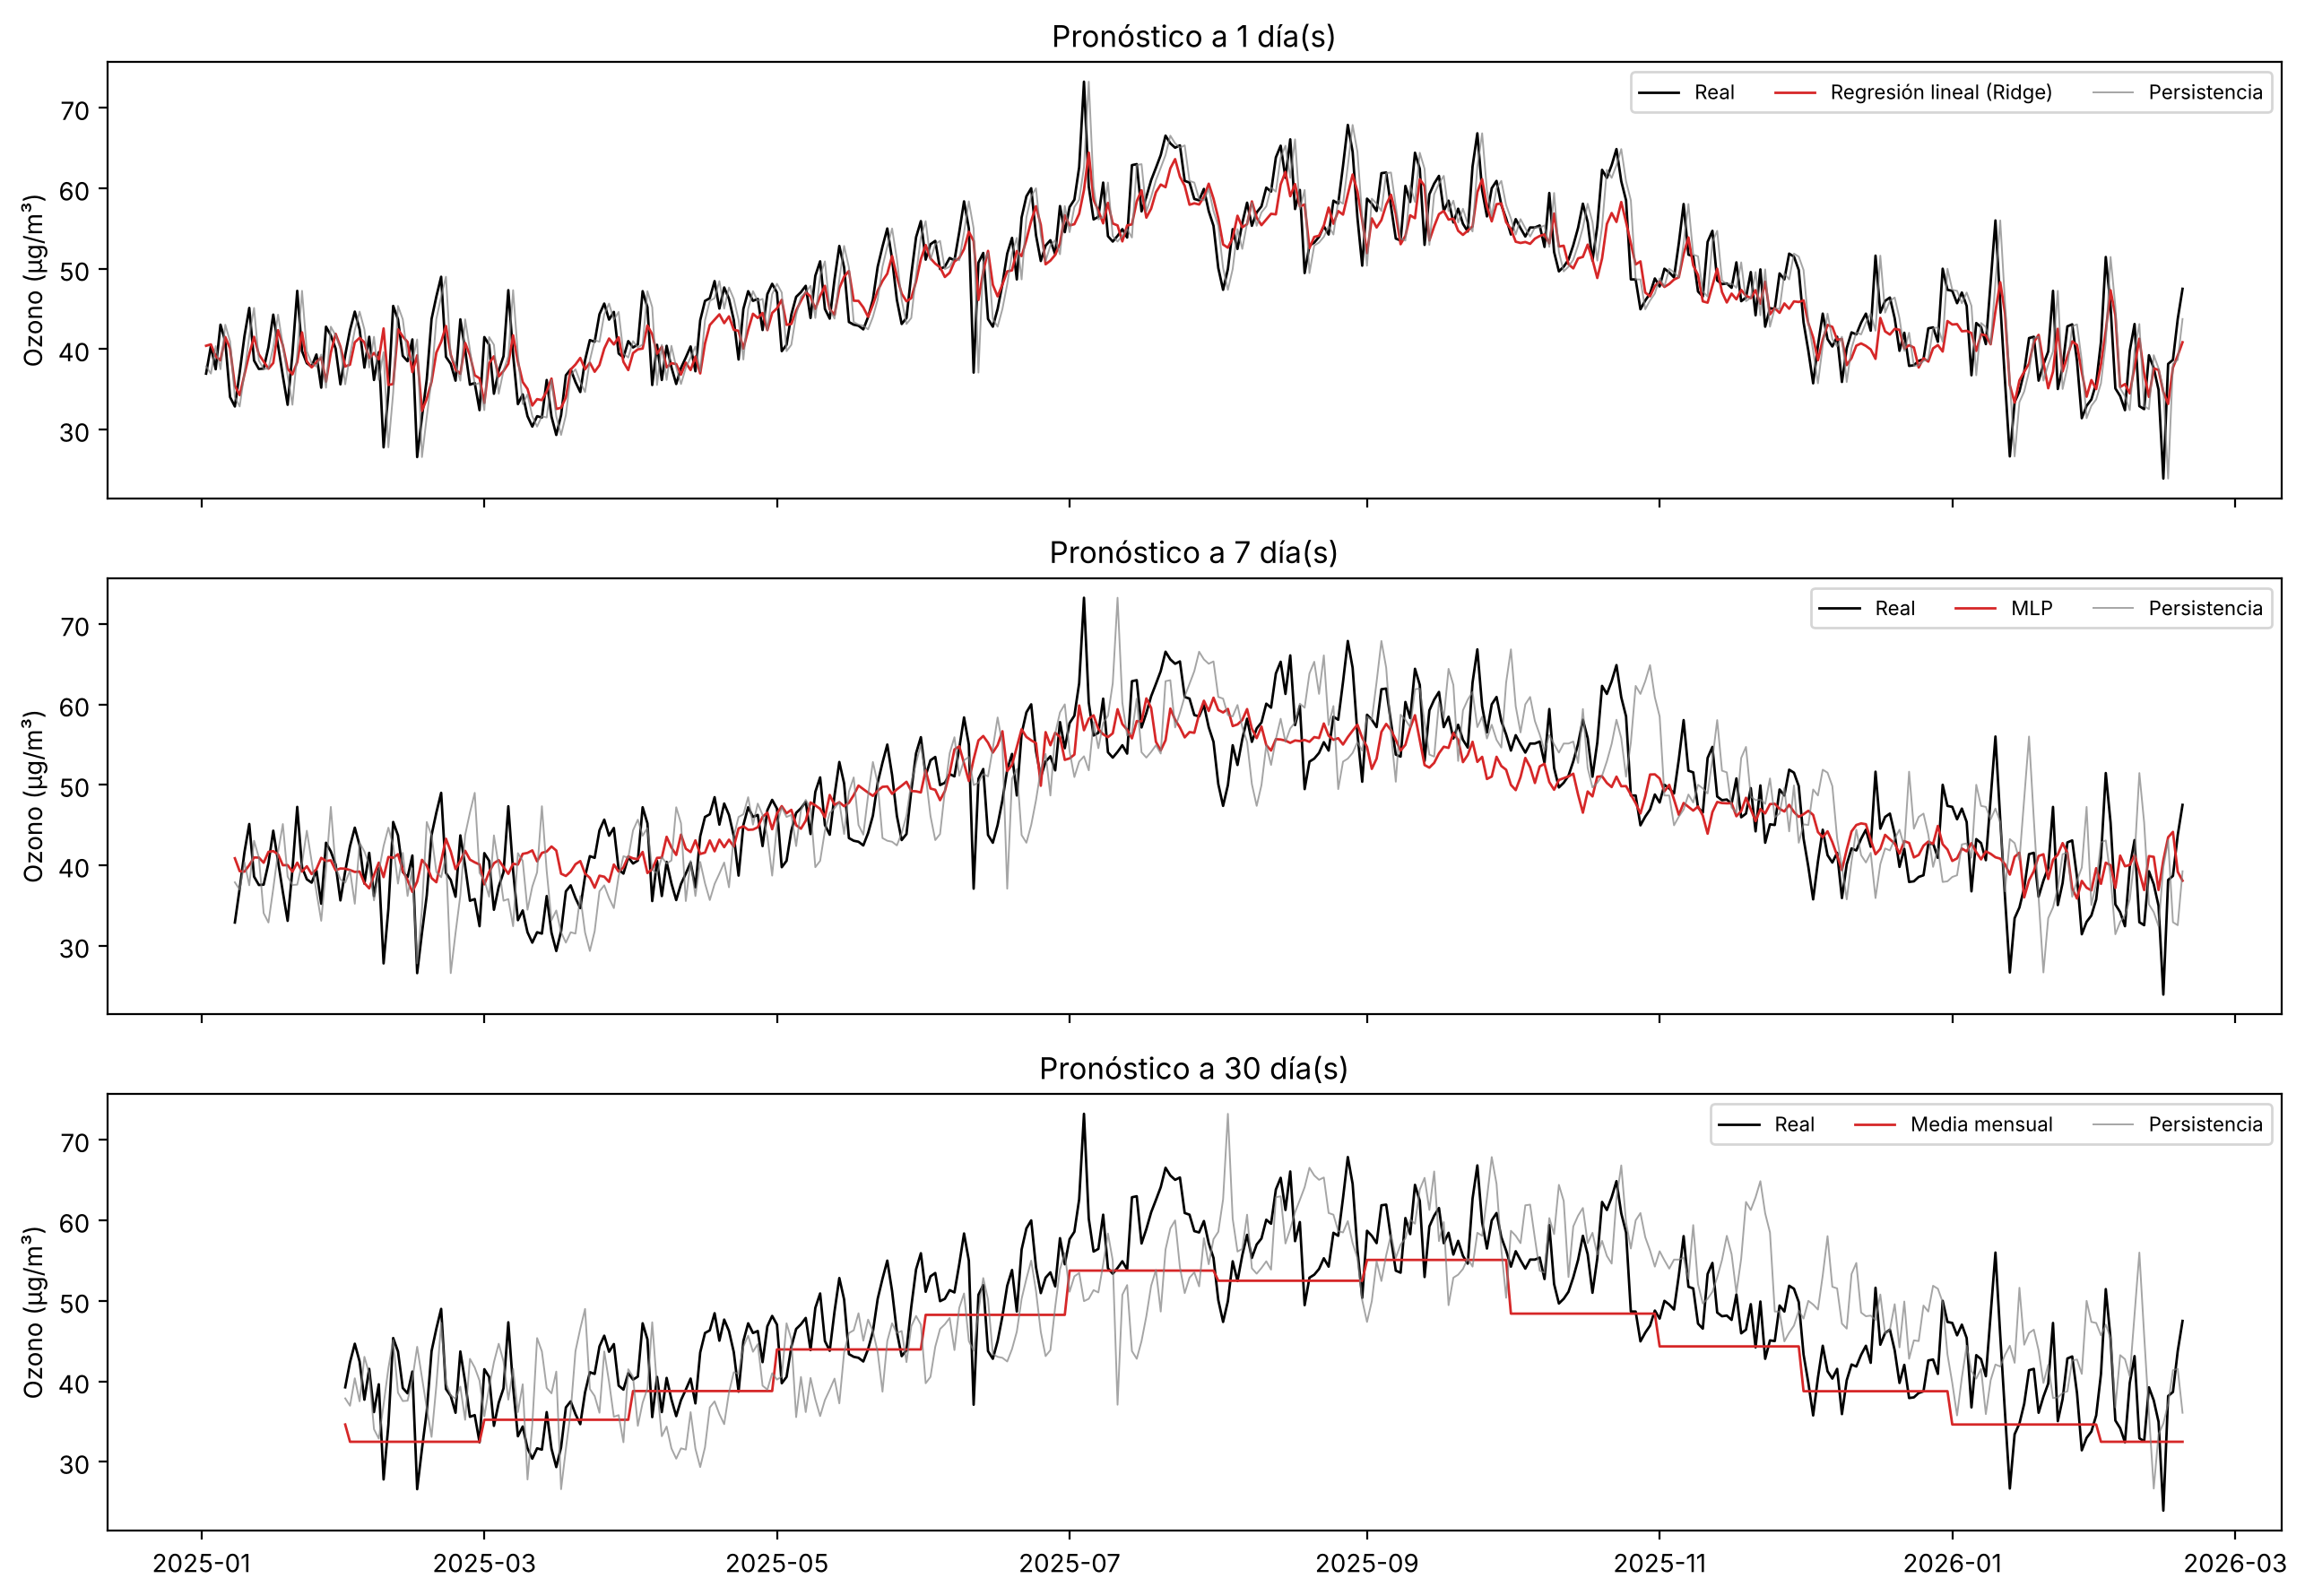

In [24]:
mejor_por_h = {h: tabla_mae.iloc[:, i].idxmin() for i, h in enumerate(HORIZONTES)}
print('Mejor modelo por horizonte:', mejor_por_h)

fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
for ax, h in zip(axes, HORIZONTES):
    y = pred_reg[h]['real']; fechas = y.index + pd.Timedelta(days=h)
    ax.plot(fechas, y.values, color='k', lw=1, label='Real')
    ax.plot(fechas, pred_reg[h][mejor_por_h[h]], color='tab:red', lw=1, label=mejor_por_h[h])
    ax.plot(fechas, pred_reg[h]['Persistencia'], color='tab:gray', lw=0.7, alpha=0.7, label='Persistencia')
    ax.set_title('Pronóstico a %d día(s)' % h); ax.set_ylabel('Ozono (µg/m³)'); ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.savefig('fig_real_vs_pred.png', dpi=150); plt.show()

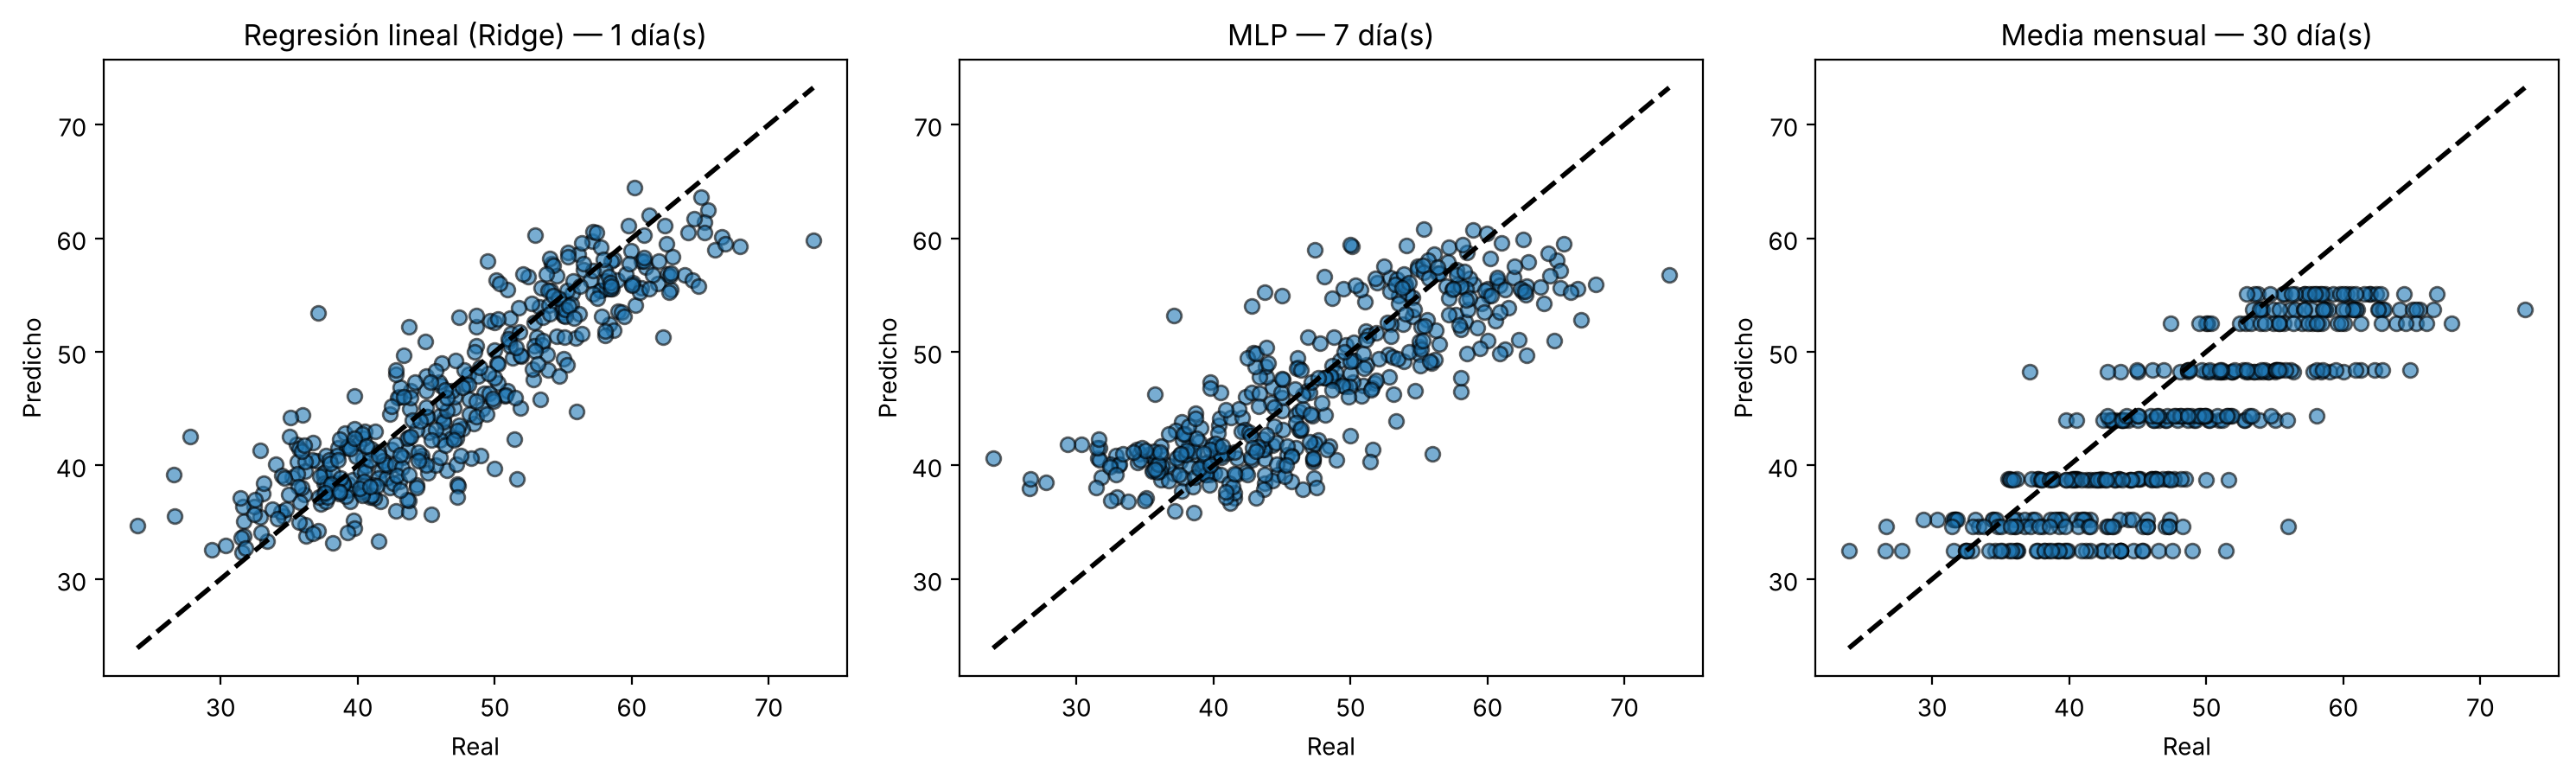

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, h in zip(axes, HORIZONTES):
    y = pred_reg[h]['real']; p = pred_reg[h][mejor_por_h[h]]
    ax.scatter(y, p, edgecolors=(0, 0, 0), alpha=0.6)
    ax.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=2)
    ax.set_xlabel('Real'); ax.set_ylabel('Predicho'); ax.set_title('%s — %d día(s)' % (mejor_por_h[h], h))
plt.tight_layout(); plt.show()

### 7.7 ¿Qué variables pesan más? (coeficientes de la regresión Ridge)

In [26]:
for h in HORIZONTES:
    gs = modelos_reg[h]['Regresión lineal (Ridge)']
    coef = pd.Series(gs.best_estimator_.named_steps['ridge'].coef_, index=gs.feature_names_in_)
    print('h=%d  →  5 entradas con mayor peso (coeficiente estandarizado):' % h)
    print(coef.reindex(coef.abs().sort_values(ascending=False).index).head(5).round(2).to_string(), '\n')

h=1  →  5 entradas con mayor peso (coeficiente estandarizado):
ozone_r0     4.30
ozone_r1     1.04
ozone_r30    0.68
ozone_r7     0.67
pm2_5_r0     0.61 

h=7  →  5 entradas con mayor peso (coeficiente estandarizado):
ozone_r7    1.33
ozone_r0    1.10
ozone_r1    1.08
mes_cos    -1.02
mes_sen    -0.72 

h=30  →  5 entradas con mayor peso (coeficiente estandarizado):
mes_cos       -2.49
ozone_r14      1.30
ozone_r1       1.11
ozone_r30      1.05
uv_index_r0   -0.90 



### 7.8 Comparación: ¿qué pasa si se usan las 9 variables (incluidas las del quiebre)?

In [27]:
res_reg9, pred_reg9, _ = experimento_regresion(VARS, mostrar_curvas=False)

=== Horizonte 1 día(s)
  Regresión lineal           CV=-7.917  {}


  Regresión lineal (Ridge)   CV=-6.024  {'ridge__alpha': 100}


  Árbol de decisión          CV=-3.571  {'decisiontreeregressor__max_depth': 5, 'decisiontreeregressor__min_samples_leaf': 20}


  KNN                        CV=-5.243  {'kneighborsregressor__n_neighbors': 50, 'kneighborsregressor__weights': 'distance'}


  MLP(16)     val_loss=1.6579 (mejor época: 12)


  MLP(64-32)  val_loss=3.7669 (mejor época: 76)


... (9 outputs left out)

  KNN                        CV=-5.868  {'kneighborsregressor__n_neighbors': 50, 'kneighborsregressor__weights': 'distance'}


  MLP(16)     val_loss=0.9931 (mejor época: 3)


  MLP(64-32)  val_loss=1.6655 (mejor época: 31)


  MLP elegido: MLP(16) | MAE en test por semilla: 46.55 ± 15.70


In [28]:
tabla_mae9 = res_reg9.pivot(index='Modelo', columns='h', values='MAE').loc[ORDEN]
comparacion = pd.concat({'6 variables estables (32 entradas)': tabla_mae.set_axis(HORIZONTES, axis=1),
                         '9 variables (47 entradas)': tabla_mae9}, axis=1).round(2)
comparacion.to_csv('resultados_comparacion_entradas.csv')
comparacion

6 variables estables (32 entradas)              \
                                                         1     7     30   
Modelo                                                                    
Persistencia                                           3.46  5.42  6.27   
Media mensual                                          5.29  5.30  5.33   
Regresión lineal                                       3.43  4.62  9.82   
Regresión lineal (Ridge)                               3.36  4.27  6.96   
Árbol de decisión                                      3.64  6.29  5.68   
KNN                                                    4.55  4.90  5.54   
MLP                                                    3.68  4.22  5.77   

                         9 variables (47 entradas)               
                                                1     7      30  
Modelo                                                           
Persistencia                                  3.46  5.42   6.27  
Media mensual                                 5.29  5.30   5.33  
Regresión lineal                              3.65  8.70  10.99  
Regresión lineal (Ridge)                      3.44  4.23   6.54  
Árbol de decisión                             3.64  6.14   6.06  
KNN                                           7.56  7.42  11.62  
MLP                                           8.72  8.86  21.69

## 8. Clasificación: día Favorable / Moderado / Desfavorable
Mismas entradas; ahora la salida es la clase del día *t + h*. Se usan las versiones clasificadoras de los mismos modelos (regresión logística en lugar de la lineal). Como las clases no están balanceadas, se usa `class_weight='balanced'` donde el modelo lo permite y la métrica de selección es `balanced_accuracy`, como en clase.

=== Horizonte 1 día(s)


  Regresión logística        CV=0.590  {'logisticregression__C': 10}


  Árbol de decisión          CV=0.651  {'decisiontreeclassifier__max_depth': 3, 'decisiontreeclassifier__min_samples_leaf': 10}


  KNN                        CV=0.614  {'kneighborsclassifier__n_neighbors': 20, 'kneighborsclassifier__weights': 'distance'}


  MLP(16)     val_loss=1.0186 (mejor época: 46)


  MLP(64-32)  val_loss=0.9292 (mejor época: 11)


  MLP elegido: MLP(64-32)


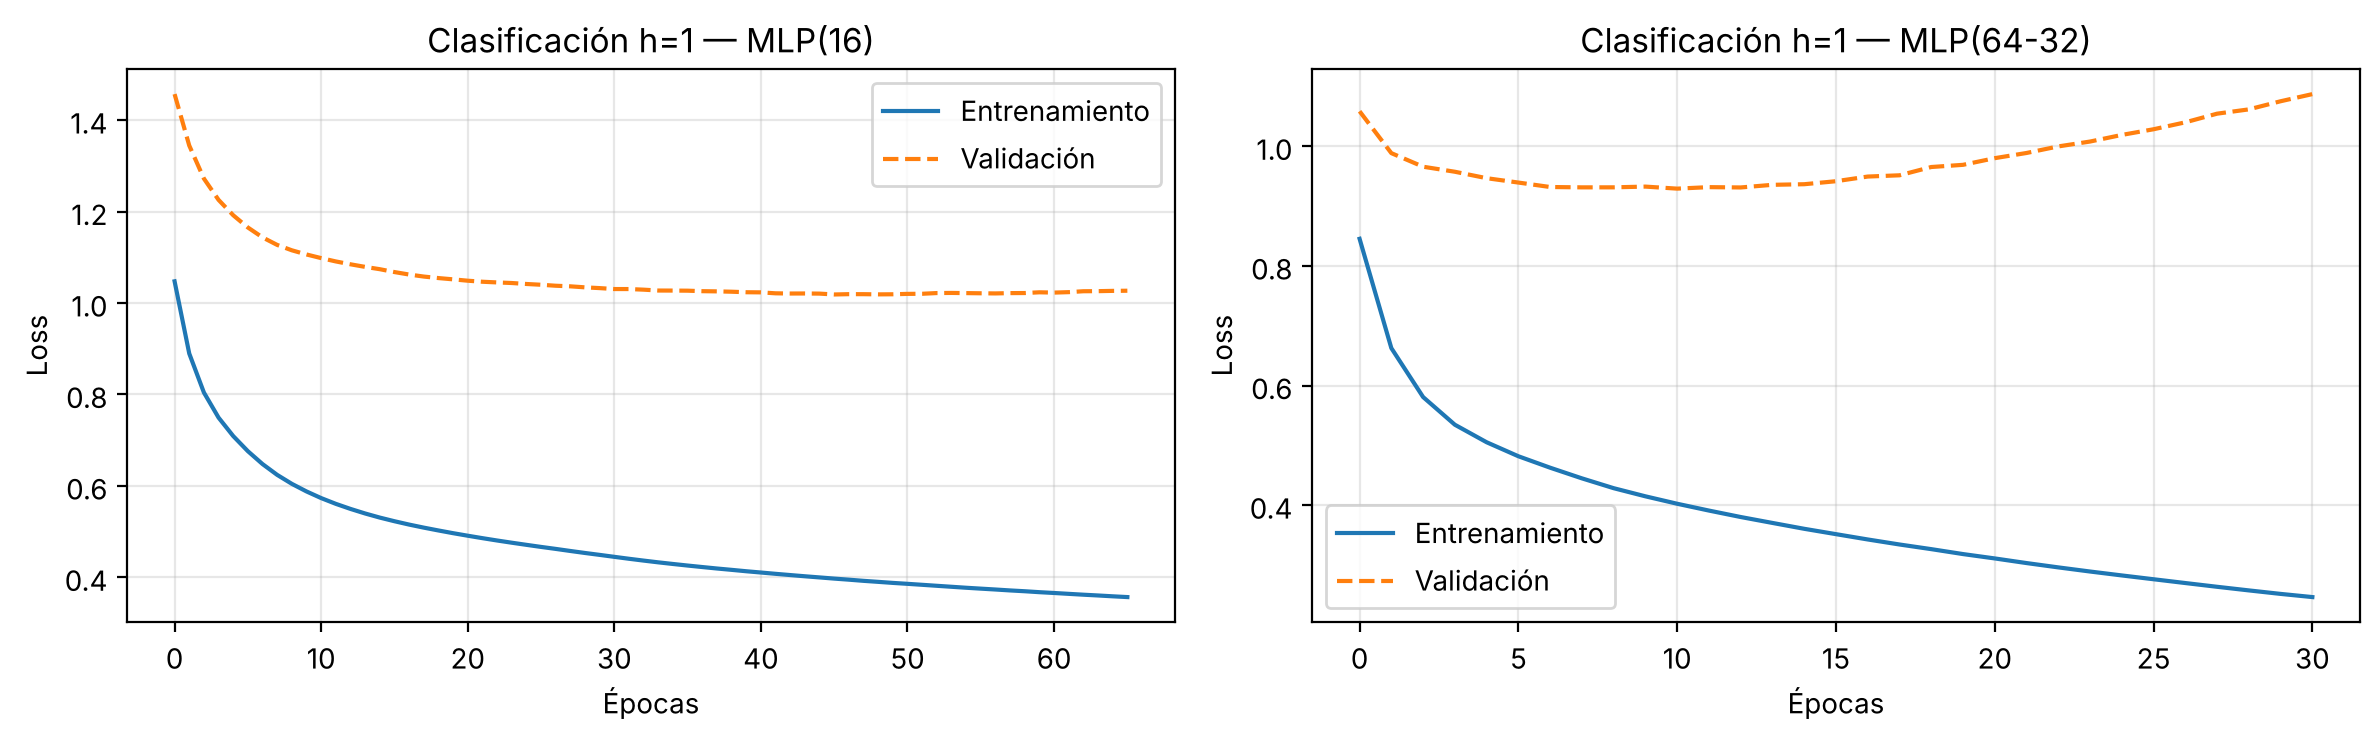

  Regresión → umbrales usa: Árbol de decisión
=== Horizonte 7 día(s)


  Regresión logística        CV=0.551  {'logisticregression__C': 0.001}


  Árbol de decisión          CV=0.549  {'decisiontreeclassifier__max_depth': 5, 'decisiontreeclassifier__min_samples_leaf': 5}


  KNN                        CV=0.578  {'kneighborsclassifier__n_neighbors': 10, 'kneighborsclassifier__weights': 'uniform'}


  MLP(16)     val_loss=1.0237 (mejor época: 50)


  MLP(64-32)  val_loss=1.0218 (mejor época: 4)


  MLP elegido: MLP(64-32)


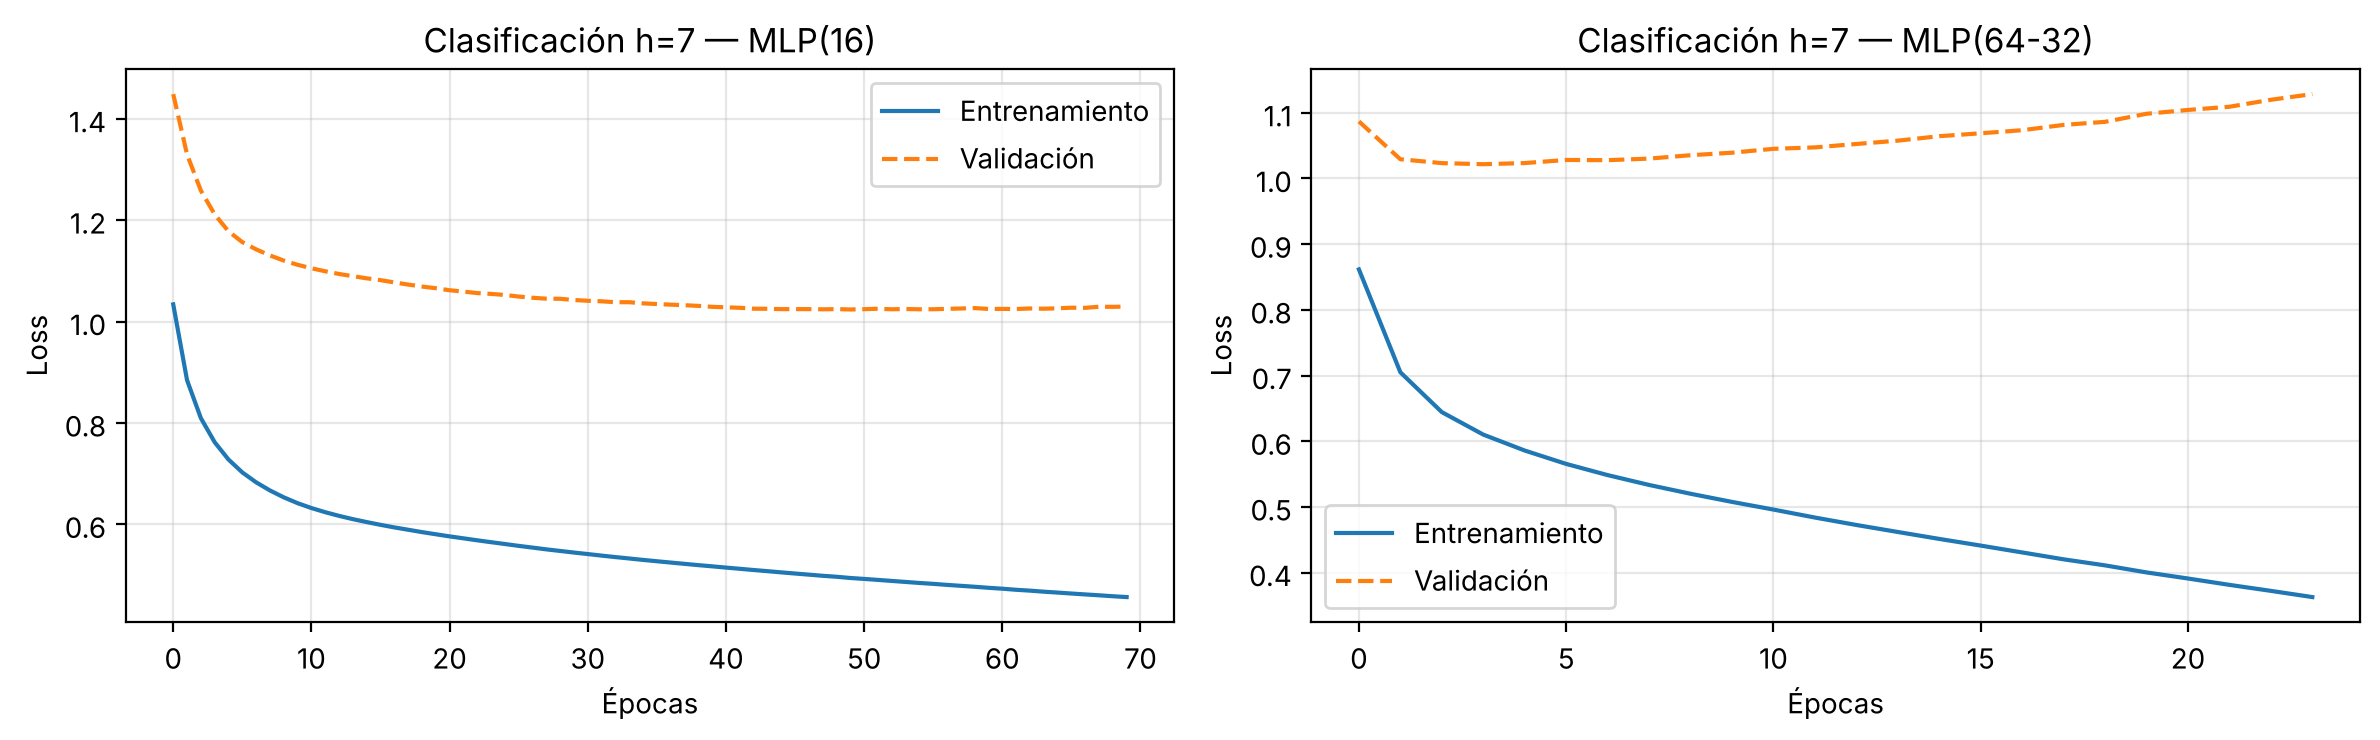

  Regresión → umbrales usa: Regresión lineal (Ridge)
=== Horizonte 30 día(s)


  Regresión logística        CV=0.523  {'logisticregression__C': 0.01}


  Árbol de decisión          CV=0.493  {'decisiontreeclassifier__max_depth': 3, 'decisiontreeclassifier__min_samples_leaf': 5}


  KNN                        CV=0.506  {'kneighborsclassifier__n_neighbors': 20, 'kneighborsclassifier__weights': 'distance'}


  MLP(16)     val_loss=0.9900 (mejor época: 11)


  MLP(64-32)  val_loss=0.9401 (mejor época: 2)


  MLP elegido: MLP(64-32)


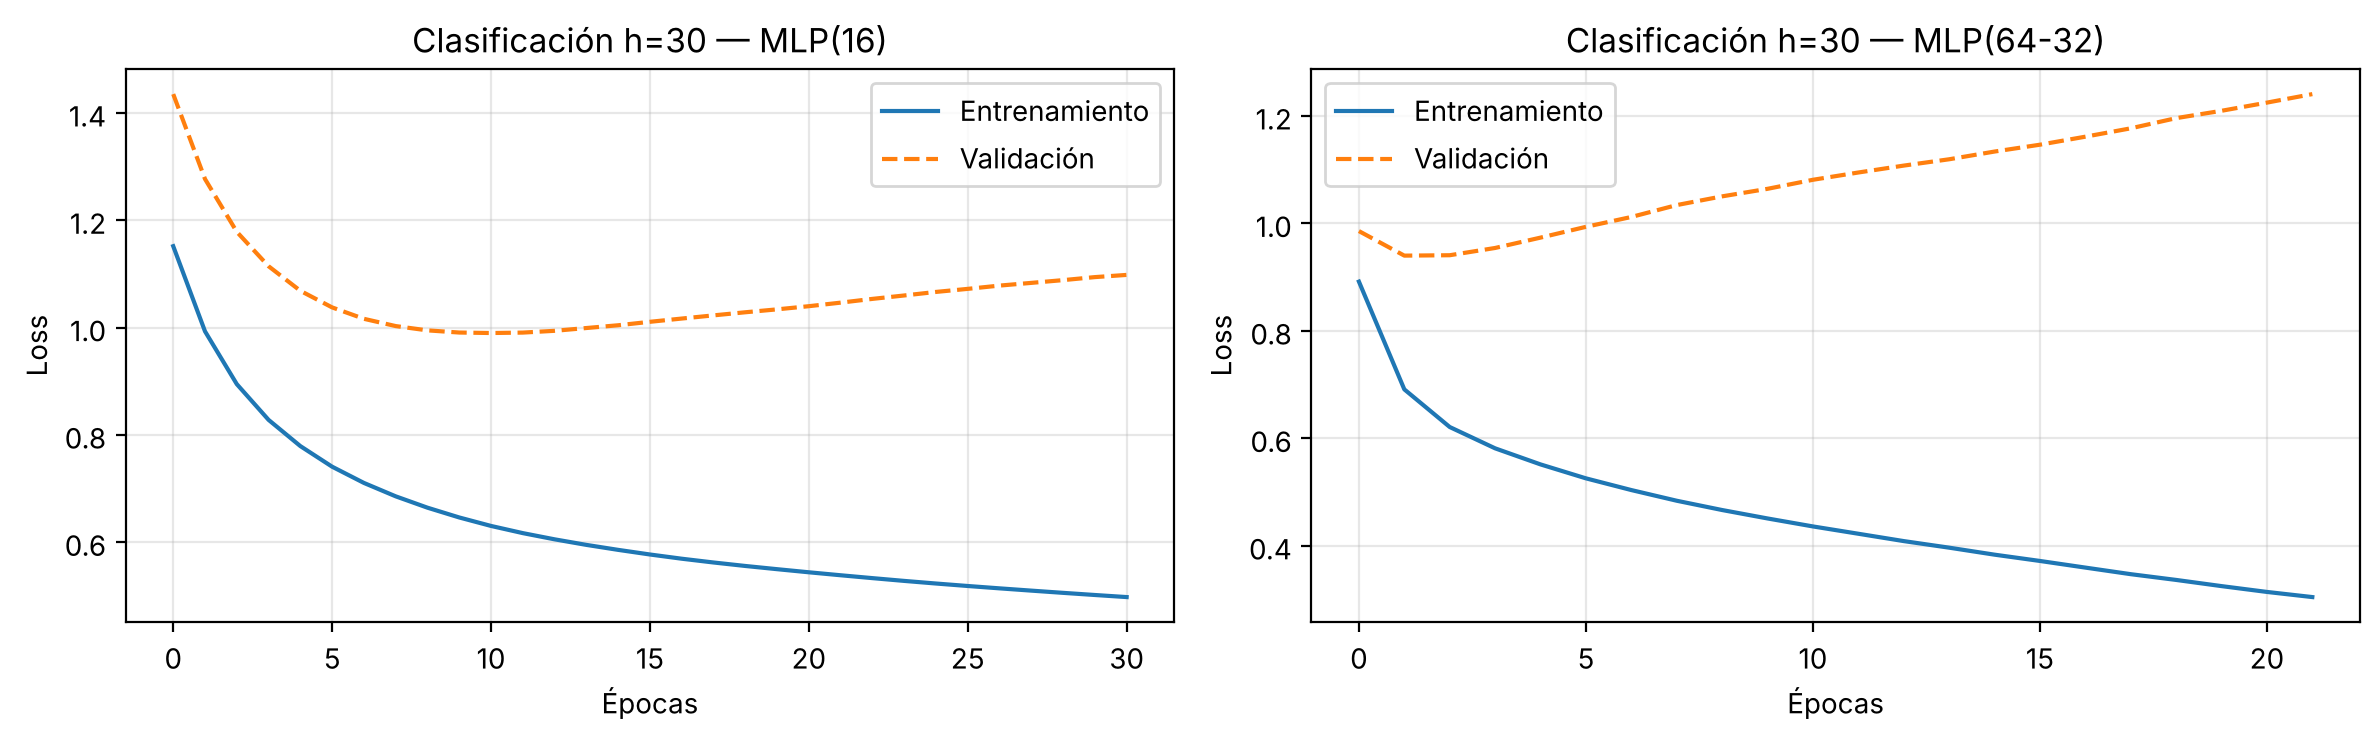

  Regresión → umbrales usa: Regresión lineal (Ridge)


In [29]:
GRILLAS_CLF = {
    'Regresión logística': (make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=5000)),
                            {'logisticregression__C': [0.001, 0.01, 0.1, 1, 10]}),
    'Árbol de decisión': (make_pipeline(StandardScaler(), DecisionTreeClassifier(class_weight='balanced', random_state=SEED)),
                          {'decisiontreeclassifier__max_depth': [3, 5, 10],
                           'decisiontreeclassifier__min_samples_leaf': [5, 10, 20, 40]}),
    'KNN': (make_pipeline(StandardScaler(), KNeighborsClassifier()),
            {'kneighborsclassifier__n_neighbors': [3, 5, 10, 15, 20, 30, 50],
             'kneighborsclassifier__weights': ['uniform', 'distance']}),
}

res_clf, pred_clf = [], {}
for h in HORIZONTES:
    print('=== Horizonte %d día(s)' % h)
    train, test = construir_dataset(df, h)
    X_train, X_test = train.drop(columns='y'), test.drop(columns='y')
    y_train = pd.Series(a_clase(train['y']), index=train.index)
    y_test  = pd.Series(a_clase(test['y']),  index=test.index)
    pred_clf[h] = {'real': y_test}
    # Referencias: clase del ozono de hoy, y clase de la media mensual
    pred_clf[h]['Persistencia']  = a_clase(pred_persistencia(test))
    pred_clf[h]['Media mensual'] = a_clase(pred_media_mensual(test, h))
    # Modelos clásicos
    mejores = ajustar_grillas(GRILLAS_CLF, X_train, y_train, h, 'balanced_accuracy')
    for nombre, gs in mejores.items():
        pred_clf[h][nombre] = gs.predict(X_test)
    # MLP con pesos de clase balanceados
    frec = np.bincount(y_train, minlength=3)
    pesos = {c: len(y_train) / (3 * frec[c]) for c in range(3)}
    preds, historias, mejor = entrenar_mlp(X_train, y_train, X_test, 'clf', pesos_clase=pesos)
    pred_clf[h]['MLP'] = np.mean(preds, axis=0).argmax(axis=1)       # promedio de probabilidades de las 5 semillas
    print('  MLP elegido:', mejor)
    plot_curvas(historias, 'Clasificación h=%d' % h)
    # Alternativa: pronosticar el número con el regresor de mejor puntaje en validación (CV) y convertirlo en clase
    mejor_cv = max(modelos_reg[h], key=lambda k: modelos_reg[h][k].best_score_)
    pred_clf[h]['Regresión → umbrales'] = a_clase(pred_reg[h][mejor_cv])
    print('  Regresión → umbrales usa:', mejor_cv)
    for nombre, p in pred_clf[h].items():
        if nombre != 'real':
            res_clf.append({'Modelo': nombre, 'h': h, **metricas_clf(y_test, p)})
res_clf = pd.DataFrame(res_clf)

### 8.1 Cuadro comparativo de clasificación (conjunto de prueba)
**F1 macro:** promedio del F1 de las tres clases (a mayor valor, mejor). **Exactitud balanceada:** promedio del *recall* de las tres clases.

In [30]:
ORDEN_C = ['Persistencia', 'Media mensual', 'Regresión logística', 'Árbol de decisión', 'KNN', 'MLP', 'Regresión → umbrales']
tabla_f1 = res_clf.pivot(index='Modelo', columns='h', values='F1macro').loc[ORDEN_C]
tabla_f1.columns = ['F1 macro 1 día', 'F1 macro 7 días', 'F1 macro 30 días']
tabla_f1.style.format('{:.3f}').highlight_max(axis=0, props='font-weight:bold; background-color:#d9ead3')

,F1 macro 1 día,F1 macro 7 días,F1 macro 30 días
Modelo,,,
Persistencia,0.745,0.602,0.557
Media mensual,0.608,0.607,0.601
Regresión logística,0.669,0.674,0.657
Árbol de decisión,0.749,0.619,0.551
KNN,0.597,0.478,0.505
MLP,0.686,0.648,0.674
Regresión → umbrales,0.677,0.682,0.488


In [31]:
tabla_ba = res_clf.pivot(index='Modelo', columns='h', values='BalAcc').loc[ORDEN_C]
tabla_ba.columns = ['Exact. bal. 1 día', 'Exact. bal. 7 días', 'Exact. bal. 30 días']
tabla_ba.style.format('{:.3f}').highlight_max(axis=0, props='font-weight:bold; background-color:#d9ead3')

,Exact. bal. 1 día,Exact. bal. 7 días,Exact. bal. 30 días
Modelo,,,
Persistencia,0.744,0.602,0.557
Media mensual,0.604,0.604,0.604
Regresión logística,0.661,0.673,0.656
Árbol de decisión,0.753,0.623,0.556
KNN,0.600,0.484,0.526
MLP,0.683,0.646,0.672
Regresión → umbrales,0.671,0.678,0.506


### 8.2 Matrices de confusión del mejor clasificador por horizonte
Se muestra, entre los cuatro modelos del curso (sin contar las referencias), el de mayor F1 macro en la prueba.

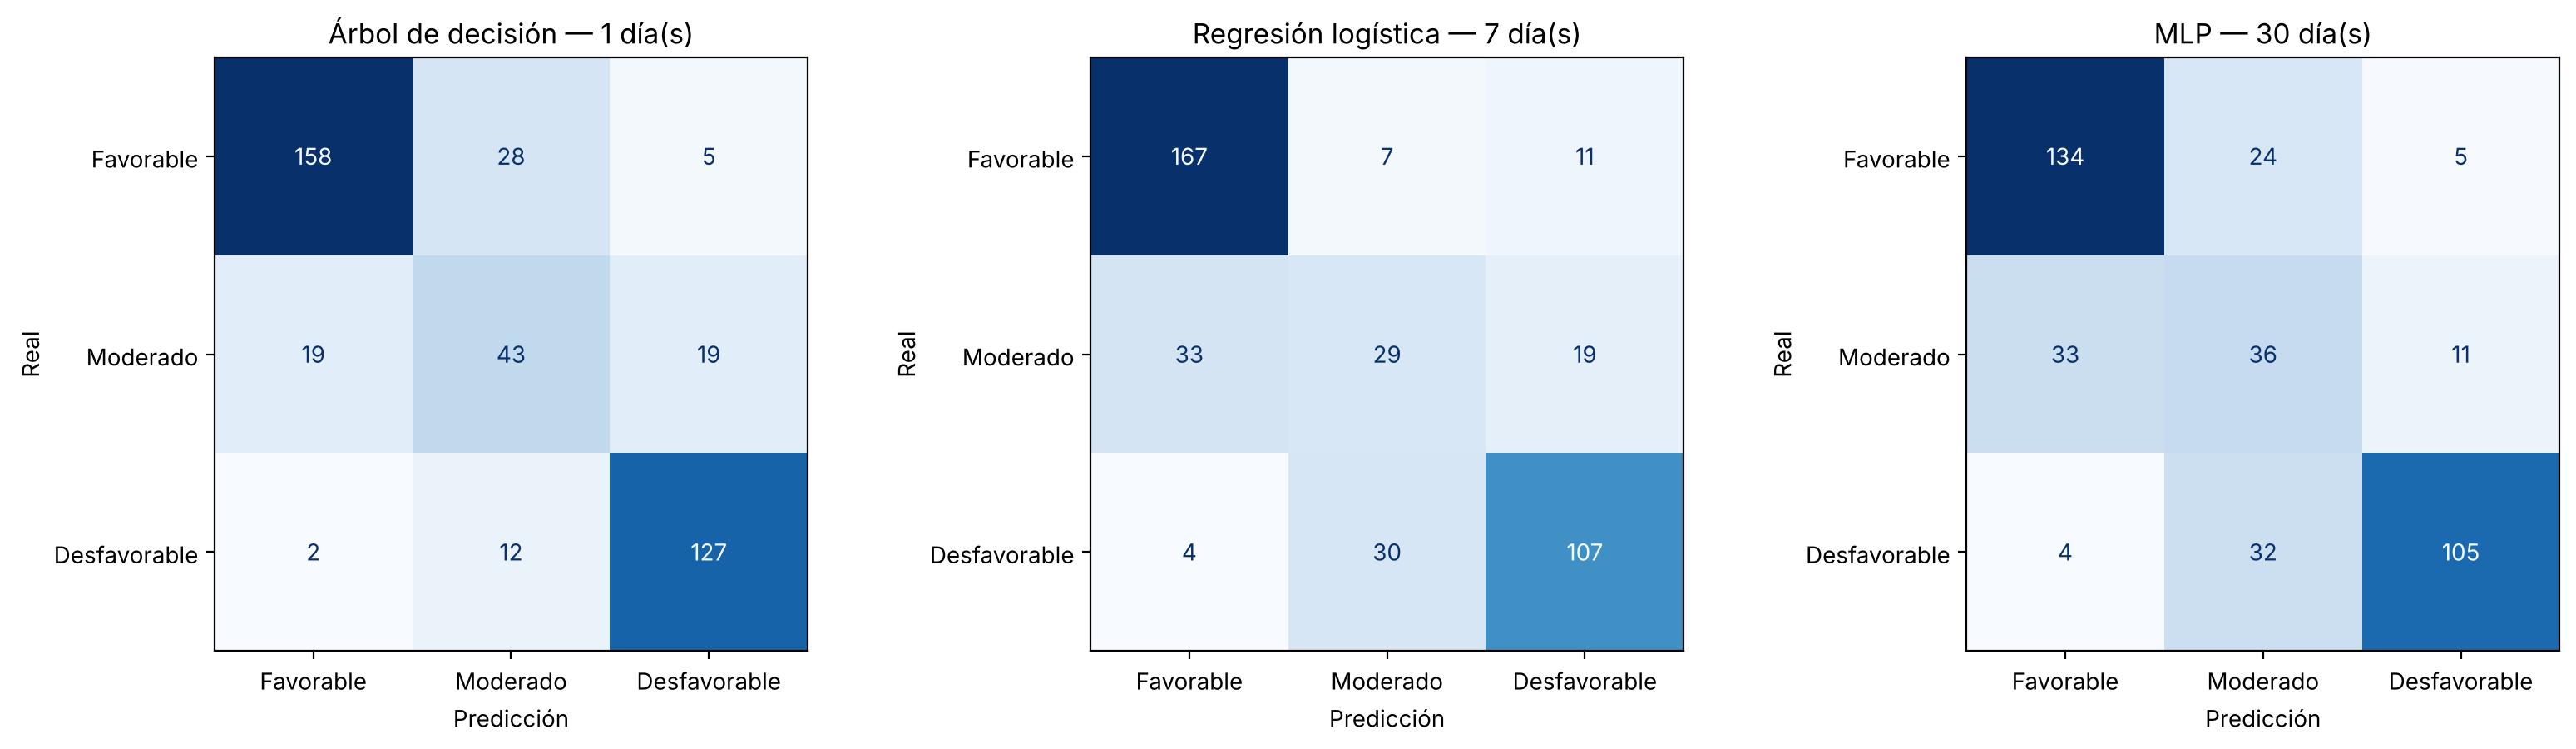

In [32]:
MODELOS_C = ['Regresión logística', 'Árbol de decisión', 'KNN', 'MLP']
mejor_clf = {h: tabla_f1.loc[MODELOS_C].iloc[:, i].idxmax() for i, h in enumerate(HORIZONTES)}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, h in zip(axes, HORIZONTES):
    cm = confusion_matrix(pred_clf[h]['real'], pred_clf[h][mejor_clf[h]], labels=[0, 1, 2])
    ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title('%s — %d día(s)' % (mejor_clf[h], h)); ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
plt.tight_layout(); plt.savefig('fig_confusion.png', dpi=150); plt.show()

In [33]:
for h in HORIZONTES:
    print('=== %s — horizonte %d día(s)' % (mejor_clf[h], h))
    print(classification_report(pred_clf[h]['real'], pred_clf[h][mejor_clf[h]], target_names=CLASES, digits=3))

=== Árbol de decisión — horizonte 1 día(s)
              precision    recall  f1-score   support

   Favorable      0.883     0.827     0.854       191
    Moderado      0.518     0.531     0.524        81
Desfavorable      0.841     0.901     0.870       141

    accuracy                          0.794       413
   macro avg      0.747     0.753     0.749       413
weighted avg      0.797     0.794     0.795       413

=== Regresión logística — horizonte 7 día(s)
              precision    recall  f1-score   support

   Favorable      0.819     0.903     0.859       185
    Moderado      0.439     0.358     0.395        81
Desfavorable      0.781     0.759     0.770       141

    accuracy                          0.744       407
   macro avg      0.680     0.673     0.674       407
weighted avg      0.730     0.744     0.735       407

=== MLP — horizonte 30 día(s)
              precision    recall  f1-score   support

   Favorable      0.784     0.822     0.802       163
    Moderad

## 9. Resumen de resultados

In [34]:
tabla_mae.round(2).to_csv('resultados_regresion_mae.csv')
tabla_det.to_csv('resultados_regresion_detalle.csv')
tabla_f1.round(3).to_csv('resultados_clasificacion_f1.csv')
tabla_ba.round(3).to_csv('resultados_clasificacion_exactitud_balanceada.csv')
print('Mejor regresor por horizonte (menor MAE en prueba):       ', mejor_por_h)
print('Mejor clasificador por horizonte (mayor F1 macro en prueba):', mejor_clf)
mejora = (1 - tabla_mae.drop(index=['Persistencia', 'Media mensual']).min() / tabla_mae.loc[['Persistencia', 'Media mensual']].min()) * 100
print('\nMejora del mejor modelo frente a la mejor referencia (MAE, %):')
print(mejora.round(1).to_string())

Mejor regresor por horizonte (menor MAE en prueba):        {1: 'Regresión lineal (Ridge)', 7: 'MLP', 30: 'Media mensual'}
Mejor clasificador por horizonte (mayor F1 macro en prueba): {1: 'Árbol de decisión', 7: 'Regresión logística', 30: 'MLP'}

Mejora del mejor modelo frente a la mejor referencia (MAE, %):
MAE 1 día       2.8
MAE 7 días     20.3
MAE 30 días    -4.0


## 10. Conclusiones
- **A 1 día** casi no hay margen: repetir el valor de hoy (persistencia) ya es muy bueno y los modelos la igualan o la mejoran muy poco.
- **A 7 días** los modelos sí aportan: la regresión lineal regularizada (Ridge) y la red MLP reducen el error frente a ambas referencias, porque combinan el nivel reciente del ozono con la época del año.
- **A 30 días** ningún modelo de regresión supera con claridad a la media mensual histórica: a ese plazo casi toda la información útil es la estacionalidad. En clasificación, en cambio, la regresión logística y el MLP sí superan a las referencias.
- **Ningún modelo gana en todos los plazos.** En regresión el menor error lo tiene Ridge a 1 día y el MLP a 7 días (casi empatado con Ridge); en clasificación, el árbol a 1 día, la regresión logística a 7 y el MLP a 30. Los modelos lineales regularizados (Ridge, logística) son los más parejos. KNN queda por debajo de las referencias a 1 y 7 días y solo es competitivo a 30 días en regresión.
- **El hallazgo más importante es sobre los datos:** el cambio de versión del modelo CAMS (12-nov-2024) altera `dust`, `pm10` y `carbon_monoxide`. Si se usan esas variables, KNN y MLP empeoran mucho en la prueba (sección 7.8). Revisar la estabilidad de las entradas fue más decisivo que elegir el algoritmo.
- **Limitaciones:** los datos son salidas de un modelo global (no mediciones de estaciones), promedios diarios de un solo punto, con poco más de tres años de historia; las clases usan umbrales propios (percentiles), no límites normativos.